# Ensemble-mean inference on HARP 11930 — the 672 hr ensemble

The 10-member **672 hr** bootstrap ensemble, run on **one holdout frame** and combined
into an **ensemble mean**. Each member was fine-tuned on a 672-sample (one-month,
hourly-cadence) bootstrap replicate — **4x** the 168-sample replicates behind
`view_harp11930_ensemble_mean.ipynb`. Same frame, same ground truth, same analysis, so
the two notebooks are directly comparable; §9 does that comparison.

**The frame: HARP 11930 @ 2024-10-01 12:00.** A nine-region complex
(NOAA 13834, 13835, 13836, 13839, 13842, 13843, 13844, 13846, 13847) covering
681,343 million km², face-on at the frame instant, and — uniquely among the three
largest holdout ARs — **not flaring in EUV at that instant**. The other two
(HARP 11786, 12094) show EUV brightening on the mask when their peak frame is taken,
so member spread there would be confounded by transient emission the models never
saw in training. Here it is not.

| produced by | what | where |
|---|---|---|
| `run_bootstrap_inference.py --regime 672hr` | AR probability per member | `672hr_infer_holdout_top3/20241001_1200/prob_<member>.nc` |
| `run_bootstrap_inference.py --regime 672hr` | normalized model input | `…/20241001_1200/channels.nc` |
| `run_bootstrap_inference.py --regime 672hr` | one row per inference | `672hr_infer_holdout_top3/manifest.csv` |
| `flare_context.py` | flare/EUV state at the instant | `672hr_infer_holdout_top3/flare_context.csv` |
| SuryaBench AR benchmark | ground-truth mask | `assets/surya-bench-ar-segmentation/data/2024/10/20241001_1200.h5` |
| this notebook (§8) | the combined ensemble + §6's boundary scalars | `…/20241001_1200/ensemble_mean.nc` |

`flare_context.csv` is copied from the 168 hr directory, not regenerated: it describes the
*frame* — GOES events, EUV state on the mask, the mask's own positive fraction — and reads
no model output, so it is identical across regimes. §1 re-derives its one load-bearing
number independently anyway.

## Three caveats, up front

**1. 2024 is outside the training span.** Every member was fine-tuned on 672 frames
drawn from 2011–2019. Nothing here was seen, and nothing from this phase of cycle 25
was seen either.

**2. The class balance is ~6x shifted, so IoU here is not comparable to the numbers
the members were selected on.** The shared 200-frame validation set has a true AR pixel
fraction of **0.00643**. This frame's mask is **0.0387** — six times denser. IoU on a
3.87 % positive class is mechanically easier than on a 0.643 % one, so the
member-selection IoUs (**0.5177–0.6341**) are **context, not a baseline**.

**3. "Best epoch" is doing more work here than in the 168 hr regime.** These runs peak
early — epochs 0–3 of 5 — and most then collapse outright (boot02 to IoU 0.0000, boot06
to 0.0572, boot03 to 0.1935). `boot08` peaks at **epoch 0**, making it a one-epoch model.
All ten are included because the ensemble is defined as every run's best checkpoint, but
the members are consequently less uniformly trained than the 168 hr ten, and that is a
candidate explanation for any spread difference §9 finds.

## What "mean inference" means here

Three distinct quantities, because the first two can disagree pixel-for-pixel:

- **soft mean** — $\bar p = \frac{1}{10}\sum_m p_m$, and the ensemble prediction is
  $\bar p > 0.5$. **This is the primary result.**
- **hard vote** — $\#\{m : p_m > 0.5\} \ge 6$. Shown for comparison. The two rules
  genuinely split; which one you want is a decision, not a detail.
- **uncertainty** — two readings, both reported. In *probability* space, the per-pixel sd
  across the ten members and the agreement count $k/10$ (§3). In *position* space, how
  far the $\bar p = 0.5$ boundary could move — the mean uncertainty about the inferred
  boundary, in px / arcsec / km (§6), together with how far that boundary actually sits
  from the true one.


## Setup

In [1]:
import os
import sys

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml
from matplotlib.colors import ListedColormap, Normalize

if "." not in sys.path:
    sys.path.insert(0, ".")
import ensemble_viz as ev  # palette + raster helpers, shared with the other viewers
import false_color as fcolor  # smooth_to_model_resolution / SURYA_PATCH_PX

ev.apply_rcparams()

# Read-only notebook: no torch, no GPU. Run from downstream_examples/ar_segmentation/
# so the relative asset paths resolve.
FRAME = "20241001_1200"
HARPNUM = 11930
INFER_ROOT = "/efs/bathomas/ar_seg_bootstrap/672hr_infer_holdout_top3"
FRAME_DIR = os.path.join(INFER_ROOT, FRAME)
TRUTH_PATH = f"./assets/surya-bench-ar-segmentation/data/2024/10/{FRAME}.h5"
TRUTH_KEY = "union_with_intersect"
SCALERS_PATH = "./assets/scalers.yaml"
HOLDOUT_CSV = "./assets/surya-bench-ar-segmentation/holdout_ar_large_from_test.csv"
# The 168 hr ensemble's §8 cache, for the section 9 comparison. Read by attrs only.
SIBLING_ROOT = "/efs/bathomas/ar_seg_bootstrap/168hrs_infer_holdout_top3"

THRESHOLD = 0.5  # matches evaluate_model's hardcoded threshold in finetune.py
CHANNEL = "aia94"

# Best epoch per member by validation IoU, with the IoU it scored.
# Source: run_bootstrap_inference.BEST_EPOCH_BY_REGIME["672hr"], derived from the wandb
# output.log of each run under /efs/bathomas/wandb (there is no 672hr/README.md the way
# 168hrs/README.md backs the sibling notebook). boot08's best epoch is 0 -- see caveat 3.
BEST = {
    "boot01": (2, 0.6036), "boot02": (1, 0.5608), "boot03": (2, 0.6169),
    "boot04": (1, 0.6314), "boot05": (2, 0.6341), "boot06": (1, 0.6089),
    "boot07": (3, 0.6104), "boot08": (0, 0.5177), "boot09": (1, 0.5621),
    "boot10": (2, 0.5699),
}
MEMBERS = sorted(BEST)
N = len(MEMBERS)
VOTE_MIN = 6  # hard-vote majority: k >= 6 of 10

# Training-era references. The validation set is the same 200 frames in both regimes,
# so TRUE_FRAC carries over; precision/recall are the 672hr best-epoch means (the 168hr
# ensemble sat at a dead-even 0.669/0.669, so this one is recall-leaning).
TRAIN_TRUE_FRAC = 0.00643
TRAIN_PREC, TRAIN_REC = 0.7306, 0.7604

scalers = yaml.safe_load(open(SCALERS_PATH))

print(f"frame {FRAME}  |  HARP {HARPNUM}  |  {N} members  |  regime 672hr\n")
for m in MEMBERS:
    p = os.path.join(FRAME_DIR, f"prob_{m}.nc")
    print(f"  prob_{m}.nc  {'ok' if os.path.exists(p) else 'MISSING'}")
print(f"  channels.nc  {'ok' if os.path.exists(os.path.join(FRAME_DIR, 'channels.nc')) else 'MISSING'}")
print(f"  ground truth {'ok' if os.path.exists(TRUTH_PATH) else 'MISSING'}")

frame 20241001_1200  |  HARP 11930  |  10 members  |  regime 672hr

  prob_boot01.nc  ok
  prob_boot02.nc  ok
  prob_boot03.nc  ok
  prob_boot04.nc  ok
  prob_boot05.nc  ok
  prob_boot06.nc  ok
  prob_boot07.nc  ok
  prob_boot08.nc  ok
  prob_boot09.nc  ok
  prob_boot10.nc  ok
  channels.nc  ok
  ground truth ok


### Loaders

The probability maps and the mask are stored on the **same raster**: north-up,
`crpix` 2048.5, 0.6 arcsec/px, 4096². That is the geometry of the `.nc` cubes the
model consumed, not the raw HMI WCS, so prediction and truth are directly comparable
pixel-for-pixel with **no reprojection**. §1 checks that by re-deriving the mask's
positive fraction and comparing it against what `flare_context.py` independently
reported.

In [2]:
def load_probability(member):
    """One member's AR probability map, as float32 (H, W)."""
    with xr.open_dataset(os.path.join(FRAME_DIR, f"prob_{member}.nc"),
                         engine="h5netcdf") as ds:
        return ds.ar_probability.values.astype(np.float32)


def load_channel(channel):
    """One channel image in display units.

    Stored standardized; this undoes only the standardization, leaving the signum-log
    values the scaler's min/max (and so the colour bar) describe. Same choice as
    infer_file.to_display_units, and deliberately not a full inverse -- undoing the
    log too would put the image on a different scale than its own colour bar.
    """
    with xr.open_dataset(os.path.join(FRAME_DIR, "channels.nc"),
                         engine="h5netcdf") as ds:
        normalized = ds[channel].values.astype(np.float32)
    s = scalers[channel]
    return normalized * (s["std"] + s["epsilon"]) + s["mean"]


def load_truth():
    """Ground-truth AR mask as bool (H, W). Stored 0/255 uint8."""
    with h5py.File(TRUTH_PATH, "r") as f:
        return f[TRUTH_KEY][:] > 0


def binary_metrics(pred, truth):
    """IoU / precision / recall for one boolean prediction against one truth mask.

    Denominators are guarded: a member predicting nothing would otherwise divide by
    zero in precision rather than scoring the 0.0 it earned.
    """
    tp = int(np.count_nonzero(pred & truth))
    fp = int(np.count_nonzero(pred & ~truth))
    fn = int(np.count_nonzero(~pred & truth))
    return {
        "iou": tp / (tp + fp + fn) if tp + fp + fn else 0.0,
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / (tp + fn) if tp + fn else 0.0,
        "pred_frac": float(pred.mean()),
    }

## 1. The frame, and a geometry check

The AR's catalog row, the flare state at the instant, and the one number that has to
agree between this notebook and `flare_context.py`: the mask's positive fraction. If
the mask were being read with a different orientation or a different key, this is
where it would show.

In [3]:
holdout = pd.read_csv(HOLDOUT_CSV).set_index("harpnum")
row = holdout.loc[HARPNUM]
flare = pd.read_csv(os.path.join(INFER_ROOT, "flare_context.csv")).set_index("frame").loc[FRAME]

truth = load_truth()
truth_frac = float(truth.mean())

print(f"HARP {HARPNUM}  @  {row.peak_timestamp}      (holdout_ar_large_from_test rank {row['rank']})")
print(f"  area                 {row.area_km2_million:,.0f} million km^2")
print(f"  extent               {row.extent_lat_km:,.0f} km lat  x  {row.extent_lon_km:,.0f} km lon")
print(f"  centroid             lat {row.lat_fwt:+.2f}  lon {row.lon_fwt:+.2f}   ({row.position})")
print(f"  duration on disk     {row.duration_days:.1f} days")
print(f"  NOAA regions         {flare.noaa_num:.0f}:  {flare.noaa_ars}")
print()
print(f"  GOES flare in progress at the instant     {flare.goes_in_progress}")
print(f"  EUV brightening on the mask               {flare.euv_on_mask_in_progress}"
      "   <- the reason this frame was chosen")
print(f"  nearest GOES event                        {flare.nearest_goes_class} "
      f"at {flare.nearest_goes_hours:+.2f} h")
print(f"  max GOES class in +/-24 h window          {flare.max_goes_class_in_window} "
      f"({flare.n_goes_events_in_window:.0f} events)")
print()
print("geometry check -- mask positive fraction")
print(f"  this notebook           {truth_frac:.6f}  ({100 * truth_frac:.3f} % of frame)")
print(f"  flare_context.py        {flare.mask_pos_frac:.6f}")
agree = abs(truth_frac - flare.mask_pos_frac) < 5e-5
print(f"  agree to <5e-5          {agree}" + ("" if agree else "   *** MISMATCH ***"))
print()
print(f"class balance vs training era:  {truth_frac:.5f} / {TRAIN_TRUE_FRAC:.5f} = "
      f"{truth_frac / TRAIN_TRUE_FRAC:.2f}x denser")

HARP 11930  @  2024-10-01 12:00:00      (holdout_ar_large_from_test rank 3)
  area                 681,343 million km^2
  extent               422,315 km lat  x  1,613,354 km lon
  centroid             lat -13.03  lon -0.09   (Face on)
  duration on disk     23.1 days
  NOAA regions         9:  13834 13835 13836 13839 13842 13843 13844 13846 13847

  GOES flare in progress at the instant     False
  EUV brightening on the mask               False   <- the reason this frame was chosen
  nearest GOES event                        C4.9 at +1.48 h
  max GOES class in +/-24 h window          X7.1 (17 events)

geometry check -- mask positive fraction
  this notebook           0.038700  (3.870 % of frame)
  flare_context.py        0.038700
  agree to <5e-5          True

class balance vs training era:  0.03870 / 0.00643 = 6.02x denser


## 2. The ten members

Same input, same channel, same threshold — the only thing differing between panels is
which 672 training frames that member saw. Each panel is the `aia94` image with that
member's predicted AR mask tinted on top.

Mirrors section 1 of `view_bootstrap_ensemble.ipynb` and section 2 of the 168 hr
notebook so all three read side by side: the same grid, the same magenta fill, the same
per-panel **AR %**. What is different here is the frame (a 2024 holdout one, not a 2013
training-era one) and the regime (672-sample replicates, not 168).

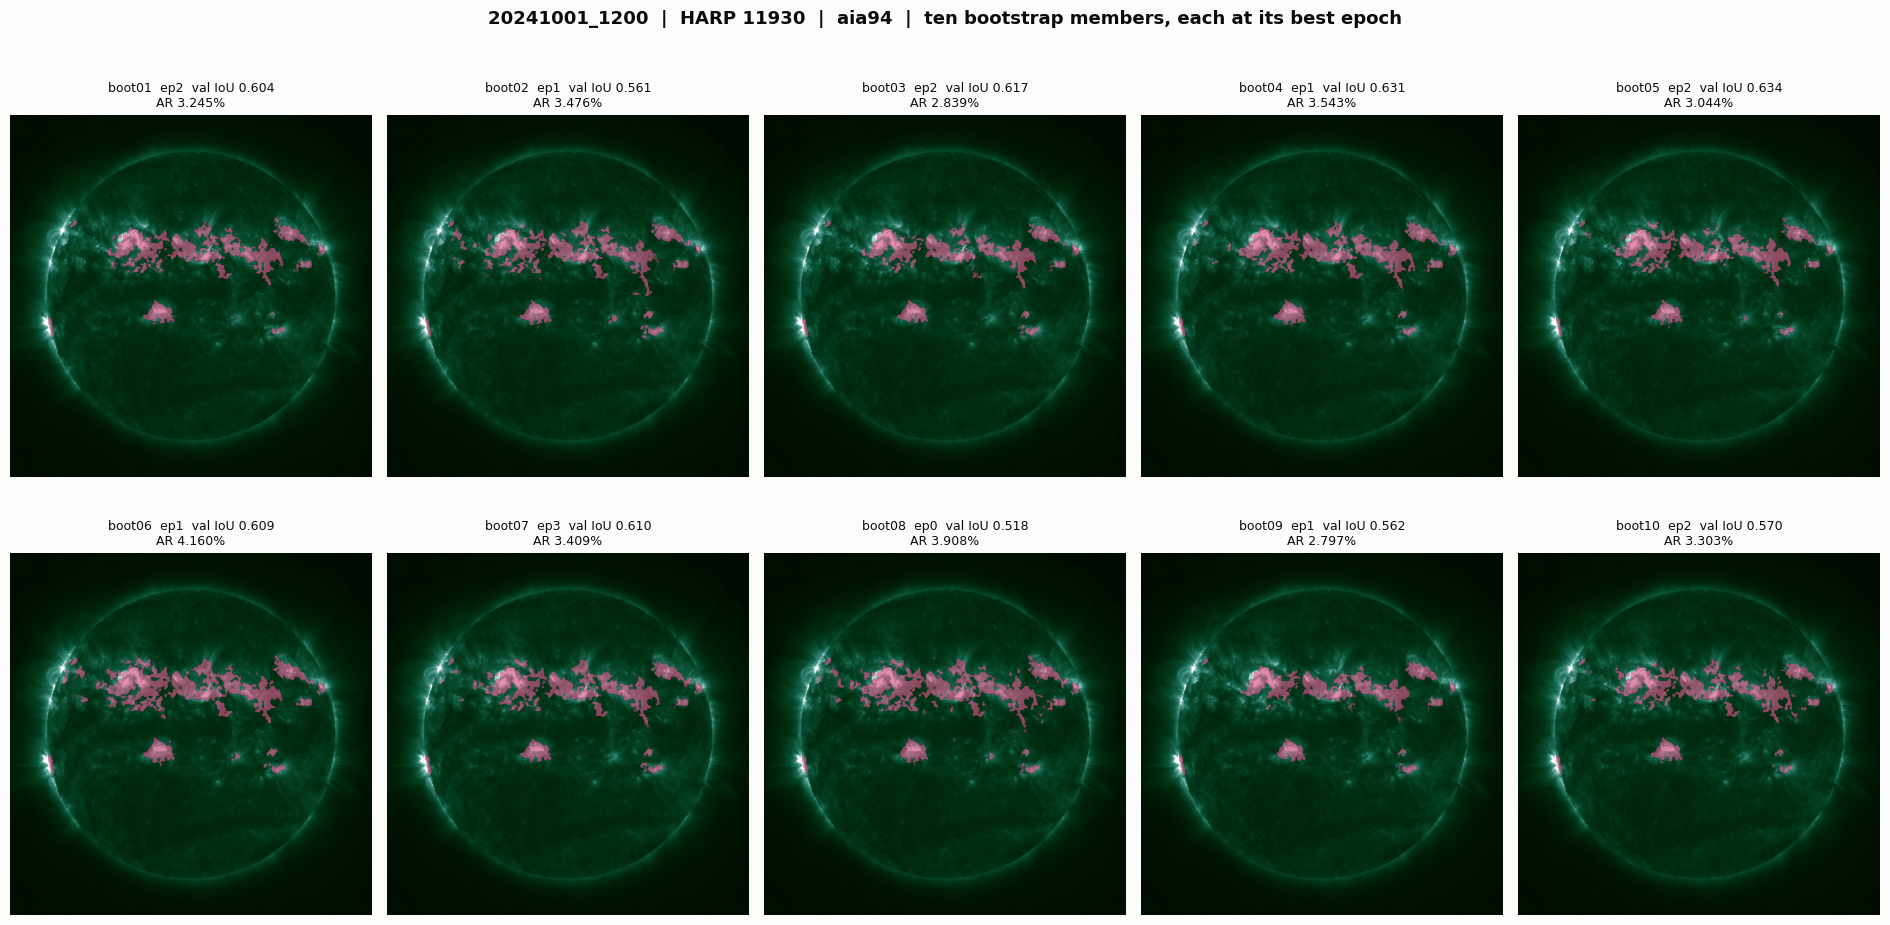

predicted AR fraction across members: mean 0.03372  sd 0.00434  (13% of mean)
  min 0.02797 (boot09)   max 0.04160 (boot06)   max/min ratio 1.49x

true AR fraction on this frame: 0.03870
  members under-predicting the area: 8 of 10   over-predicting: 2
  mean member area / true area = 0.871x
  for scale, on the 2011-2019 infer_data frames these members predicted 0.11-1.07 % AR


In [4]:
image = load_channel(CHANNEL)
vmin, vmax = ev.channel_clim(CHANNEL, image)
img_small = ev.block_mean(image, 4)

fig, axes = plt.subplots(2, 5, figsize=(19, 9.4))
fig.suptitle(
    f"{FRAME}  |  HARP {HARPNUM}  |  {CHANNEL}  |  "
    f"ten bootstrap members, each at its best epoch",
    fontsize=13, fontweight="bold", color=ev.INK, y=1.02,
)

fracs = {}
for ax, member in zip(axes.ravel(), MEMBERS):
    mask = load_probability(member) > THRESHOLD
    fracs[member] = float(mask.mean())
    epoch, iou = BEST[member]

    ax.imshow(img_small, cmap=ev.channel_cmap(CHANNEL), vmin=vmin, vmax=vmax)
    # block_max so a sparse mask survives downsampling.
    ax.imshow(np.ma.masked_where(~ev.block_max(mask, 4), np.ones_like(img_small)),
              cmap=ListedColormap([ev.MASK_FILL]), alpha=0.65, vmin=0, vmax=1)
    ax.set_title(f"{member}  ep{epoch}  val IoU {iou:.3f}\nAR {100 * fracs[member]:.3f}%",
                 fontsize=9, color=ev.INK)
    ax.axis("off")

for ax in axes.ravel()[len(MEMBERS):]:
    ax.axis("off")

# h_pad keeps the second row's two-line titles off the first row's images;
# tight_layout under-reserves for titles on axes with axis("off").
plt.tight_layout(h_pad=3.0)
plt.show()

v = np.array([fracs[m] for m in MEMBERS])
print(f"predicted AR fraction across members: mean {v.mean():.5f}  sd {v.std(ddof=1):.5f}  "
      f"({100 * v.std(ddof=1) / v.mean():.0f}% of mean)")
print(f"  min {v.min():.5f} ({min(fracs, key=fracs.get)})   "
      f"max {v.max():.5f} ({max(fracs, key=fracs.get)})   "
      f"max/min ratio {v.max() / v.min():.2f}x")
print(f"\ntrue AR fraction on this frame: {truth_frac:.5f}")
print(f"  members under-predicting the area: {int((v < truth_frac).sum())} of {N}   "
      f"over-predicting: {int((v > truth_frac).sum())}")
print(f"  mean member area / true area = {v.mean() / truth_frac:.3f}x")
print(f"  for scale, on the 2011-2019 infer_data frames these members predicted "
      "0.11-1.07 % AR")

## 3. The ensemble mean

The headline figure. Four panels: the mean probability as a continuous field, the
ensemble prediction $\bar p > 0.5$, the per-pixel spread, and the ground truth the
first three are trying to be.

Accumulated **one member at a time** — sum and sum-of-squares in float64, the way
`agreement_map` accumulates its count. Holding ten float32 4096² maps at once is
1.3 GB for no reason. The per-member metrics are computed in the same pass, since each
map is already resident when it is added; §4 only tabulates them.

In [5]:
H = W = 4096
total = np.zeros((H, W), dtype=np.float64)
total_sq = np.zeros((H, W), dtype=np.float64)
count = np.zeros((H, W), dtype=np.uint8)
member_rows = []

for member in MEMBERS:
    prob = load_probability(member)
    total += prob
    total_sq += np.square(prob, dtype=np.float64)
    count += (prob > THRESHOLD)
    epoch, val_iou = BEST[member]
    member_rows.append({"name": member, "kind": "member", "epoch": epoch,
                        "val_iou": val_iou, **binary_metrics(prob > THRESHOLD, truth)})
    del prob

p_mean = (total / N).astype(np.float32)
# var = E[p^2] - E[p]^2, population then corrected to the n-1 sample variance.
# Clipped at 0: the identity is exact in real arithmetic, but a pixel where all ten
# members agree to the last fp16 bit can land a few 1e-17 below zero.
p_var = np.clip(total_sq / N - np.square(total / N), 0.0, None) * (N / (N - 1))
p_sd = np.sqrt(p_var).astype(np.float32)
del total, total_sq, p_var

soft_pred = p_mean > THRESHOLD
hard_pred = count >= VOTE_MIN

print(f"mean probability   min {p_mean.min():.4f}  max {p_mean.max():.4f}  "
      f"frame mean {p_mean.mean():.5f}")
print(f"per-pixel sd       max {p_sd.max():.4f}  "
      f"mean over pixels where >=1 member fired {p_sd[count > 0].mean():.4f}")
print(f"agreement count    min {count.min()}  max {count.max()}  dtype {count.dtype}")
print()
print(f"soft mean  p > {THRESHOLD}   predicts AR on {100 * soft_pred.mean():.3f} % of frame")
print(f"hard vote  k >= {VOTE_MIN}      predicts AR on {100 * hard_pred.mean():.3f} % of frame")
print(f"ground truth              {100 * truth_frac:.3f} % of frame")
print()
disagree = int(np.count_nonzero(soft_pred != hard_pred))
print(f"pixels where the two rules disagree: {disagree:,} "
      f"({100 * disagree / soft_pred.size:.4f} % of frame)")

mean probability   min 0.0000  max 1.0000  frame mean 0.03496
per-pixel sd       max 0.4406  mean over pixels where >=1 member fired 0.1402
agreement count    min 0  max 10  dtype uint8

soft mean  p > 0.5   predicts AR on 3.293 % of frame
hard vote  k >= 6      predicts AR on 3.222 % of frame
ground truth              3.870 % of frame

pixels where the two rules disagree: 20,363 (0.1214 % of frame)


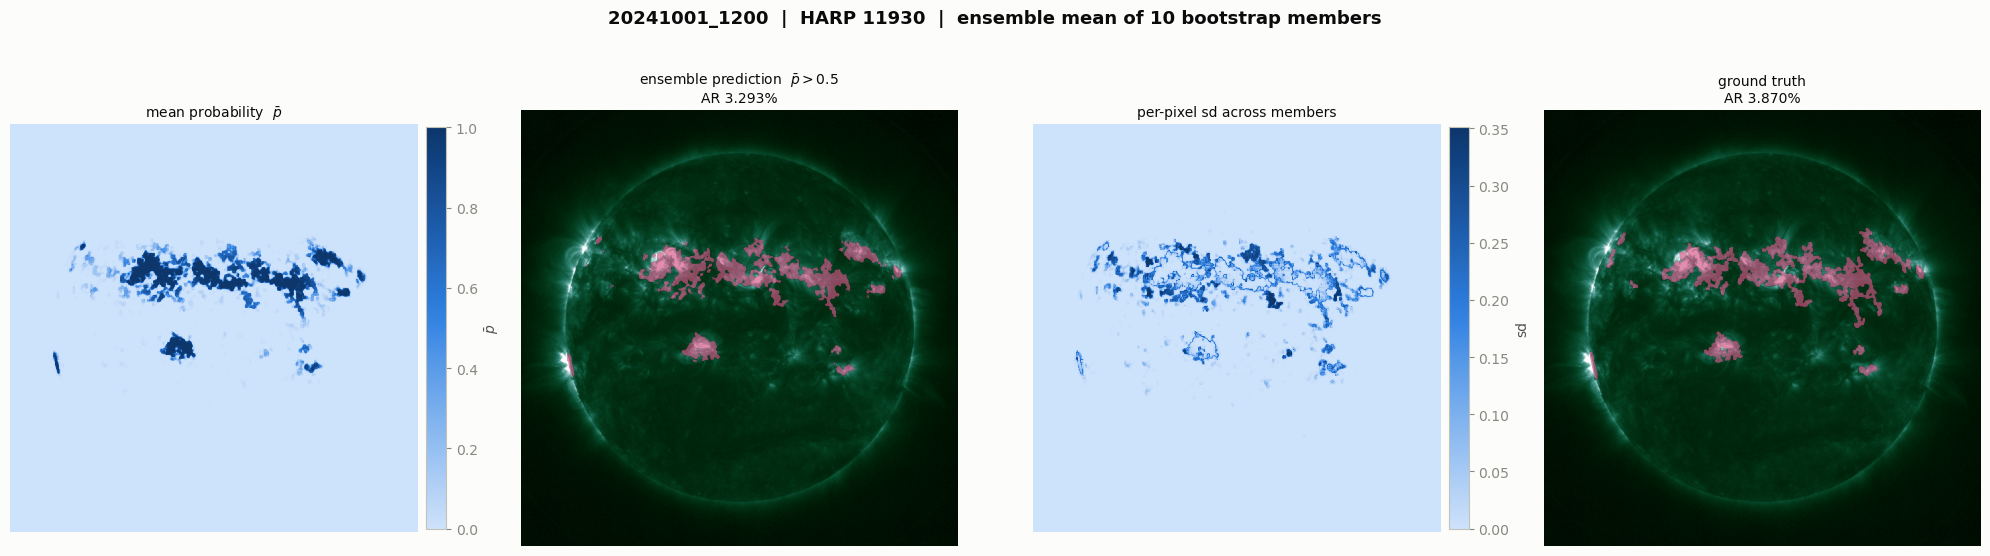

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5.6))
fig.suptitle(f"{FRAME}  |  HARP {HARPNUM}  |  ensemble mean of {N} bootstrap members",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.04)

# block_mean on the continuous fields (they are smooth), block_max on the two
# boolean masks (they are not -- a factor-4 mean would thin them).
im0 = axes[0].imshow(ev.block_mean(p_mean, 4), cmap=ev.SEQ, vmin=0, vmax=1,
                     interpolation="nearest")
axes[0].set_title(r"mean probability  $\bar p$", fontsize=10, color=ev.INK)
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.02).set_label(
    r"$\bar p$", color=ev.INK_2)

axes[1].imshow(ev.block_mean(image, 4), cmap=ev.channel_cmap(CHANNEL),
               vmin=vmin, vmax=vmax)
axes[1].imshow(np.ma.masked_where(~ev.block_max(soft_pred, 4), np.ones((H // 4, W // 4))),
               cmap=ListedColormap([ev.MASK_FILL]), alpha=0.65, vmin=0, vmax=1)
axes[1].set_title(rf"ensemble prediction  $\bar p > {THRESHOLD}$"
                  f"\nAR {100 * soft_pred.mean():.3f}%", fontsize=10, color=ev.INK)

im2 = axes[2].imshow(ev.block_mean(p_sd, 4), cmap=ev.SEQ, vmin=0,
                     vmax=float(np.percentile(p_sd[::4, ::4], 99.9)),
                     interpolation="nearest")
axes[2].set_title("per-pixel sd across members", fontsize=10, color=ev.INK)
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.02).set_label("sd", color=ev.INK_2)

axes[3].imshow(ev.block_mean(image, 4), cmap=ev.channel_cmap(CHANNEL),
               vmin=vmin, vmax=vmax)
axes[3].imshow(np.ma.masked_where(~ev.block_max(truth, 4), np.ones((H // 4, W // 4))),
               cmap=ListedColormap([ev.MASK_FILL]), alpha=0.65, vmin=0, vmax=1)
axes[3].set_title(f"ground truth\nAR {100 * truth_frac:.3f}%", fontsize=10, color=ev.INK)

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Does averaging help?

An empirical question, not a foregone one. Every member against the ground truth, plus
the soft mean, the hard vote, and — as the honest single-model baselines — the member
with the **best** IoU on this frame and the **median** member. Beating the best member
would be luck (it is chosen *using* the answer); beating the **median** member is the
claim that matters, because the median is what you would get by picking one member
blind.

Predicted-vs-true AR fraction sits in the same table, as `pred/true`. It separates the
two ways a prediction can be wrong: a row near `pred/true = 1` with a low IoU found the
right *amount* of AR in the wrong *places* (a localization failure), while a row far
from 1 got the amount wrong (a calibration failure). They call for different fixes, and
with the mask 6x denser than anything these models trained on, either is plausible here.

In [7]:
scores = pd.DataFrame(member_rows)

# Aggregates appended as rows of the same table, so the dot chart reads off one frame.
agg_rows = [
    {"name": "soft mean", "kind": "ensemble", "epoch": np.nan, "val_iou": np.nan,
     **binary_metrics(soft_pred, truth)},
    {"name": f"hard vote (k>={VOTE_MIN})", "kind": "ensemble", "epoch": np.nan,
     "val_iou": np.nan, **binary_metrics(hard_pred, truth)},
]
scores = pd.concat([scores, pd.DataFrame(agg_rows)], ignore_index=True)

members_only = scores[scores.kind == "member"].sort_values("iou")
best_member = members_only.iloc[-1]
# Lower median of the ten, so the row is a real member rather than an interpolation.
median_member = members_only.iloc[(N - 1) // 2]

scores["true_frac"] = truth_frac
scores["pred_over_true"] = scores.pred_frac / truth_frac

cols = ["name", "epoch", "val_iou", "iou", "precision", "recall", "pred_frac",
        "pred_over_true"]
display_tbl = scores[cols].copy()
display_tbl.columns = ["", "ep", "val IoU", "IoU", "precision", "recall",
                       "pred AR frac", "pred/true"]
print(display_tbl.to_string(index=False, float_format=lambda x: f"{x:.4f}", na_rep="-"))

soft = scores.set_index("name").loc["soft mean"]
hard = scores.set_index("name").loc[f"hard vote (k>={VOTE_MIN})"]
print(f"\ntrue AR fraction {truth_frac:.5f}   "
      f"(training-era validation: {TRAIN_TRUE_FRAC:.5f})")
print(f"\n{'':<22}{'IoU':>8}{'precision':>11}{'recall':>9}{'pred/true':>11}")
for label, r in [("soft mean", soft), (f"hard vote (k>={VOTE_MIN})", hard),
                 (f"best member ({best_member['name']})", best_member),
                 (f"median member ({median_member['name']})", median_member)]:
    print(f"{label:<22}{r.iou:>8.4f}{r.precision:>11.4f}{r.recall:>9.4f}"
          f"{r.pred_frac / truth_frac:>11.2f}")

d_med = soft.iou - median_member.iou
d_best = soft.iou - best_member.iou
print(f"\nsoft mean - median member : {d_med:+.4f} IoU  "
      f"({'averaging helps' if d_med > 0 else 'averaging does NOT help'})")
print(f"soft mean - best member   : {d_best:+.4f} IoU")
print(f"soft mean - hard vote     : {soft.iou - hard.iou:+.4f} IoU")
print(f"\nmember IoU spread on this frame: {members_only.iou.min():.4f} - "
      f"{members_only.iou.max():.4f}  (sd {members_only.iou.std(ddof=1):.4f})")
print(f"training-era mean precision / recall was {TRAIN_PREC:.3f} / {TRAIN_REC:.3f} "
      "-- dead even. Compare the gap here.")

                     ep  val IoU    IoU  precision  recall  pred AR frac  pred/true
          boot01 2.0000   0.6036 0.7213     0.9188  0.7704        0.0325     0.8385
          boot02 1.0000   0.5608 0.7006     0.8707  0.7820        0.0348     0.8982
          boot03 2.0000   0.6169 0.6645     0.9433  0.6921        0.0284     0.7337
          boot04 1.0000   0.6314 0.7347     0.8862  0.8113        0.0354     0.9155
          boot05 2.0000   0.6341 0.6696     0.9111  0.7165        0.0304     0.7864
          boot06 1.0000   0.6089 0.7073     0.7997  0.8597        0.0416     1.0750
          boot07 3.0000   0.6104 0.7141     0.8895  0.7836        0.0341     0.8810
          boot08 0.0000   0.5177 0.6934     0.8150  0.8230        0.0391     1.0098
          boot09 1.0000   0.5621 0.6545     0.9430  0.6815        0.0280     0.7227
          boot10 2.0000   0.5699 0.7351     0.9201  0.7853        0.0330     0.8535
       soft mean      -        - 0.7395     0.9248  0.7869        0.0329    

### The same table as a chart

Members in blue, the two ensemble rules in orange — the **emphasis** form, because the
story is the two aggregate rows, not ten equally-interesting ones. Sorted by IoU, so
where the ensemble lands in the member ordering is the whole read. The median member is
marked with a reference line rather than a third colour: it *is* one of the ten, and a
third hue would imply a third kind of thing.

A **dot plot, not a lollipop** — position encodes the value and nothing encodes length,
so the axes are free to zoom to the data. Stems to a zero baseline would be the honest
choice if length carried meaning, but here they would spend 90 % of the axis on the
empty 0–0.6 range and flatten the twelve rows into one indistinguishable column. Each
panel instead carries the reference line that makes its numbers mean something: the
median member on the left, `pred = truth` on the right.

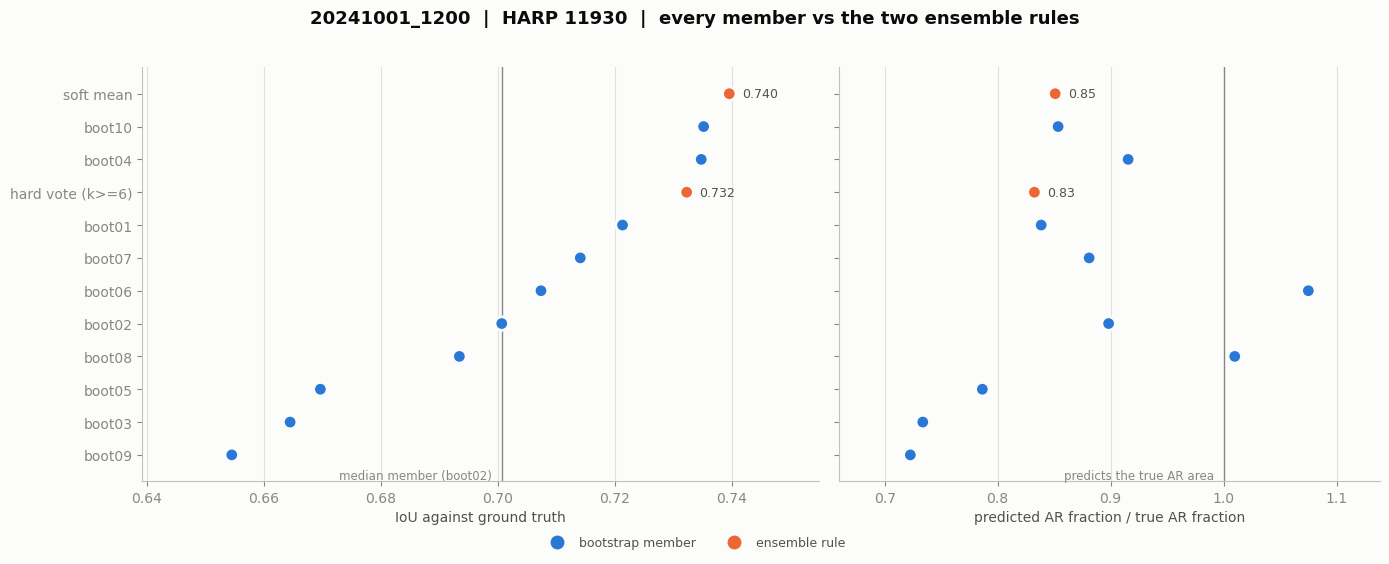

In [8]:
chart = scores.sort_values("iou").reset_index(drop=True)
y = np.arange(len(chart))
colours = [ev.SERIES_2 if k == "ensemble" else ev.SERIES_1 for k in chart.kind]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True,
                         gridspec_kw={"width_ratios": [1.25, 1]})
fig.suptitle(f"{FRAME}  |  HARP {HARPNUM}  |  every member vs the two ensemble rules",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.02)

def zoomed_xlim(values, pad=0.18):
    """Data range plus a margin. Legitimate here only because nothing encodes length."""
    lo, hi = float(np.min(values)), float(np.max(values))
    m = max((hi - lo) * pad, 0.01)
    return lo - m, hi + m


# ---- left: IoU, against the median-member baseline
ax = axes[0]
ratio = chart.pred_frac / truth_frac
ax.axvline(median_member.iou, color=ev.MUTED, lw=1.0, zorder=1)
# 2px surface ring so dots stay legible where rows crowd (marks-and-anatomy).
ax.scatter(chart.iou, y, s=95, c=colours, zorder=3,
           edgecolors=plt.rcParams["figure.facecolor"], linewidths=2)
ax.set_yticks(y)
ax.set_yticklabels(chart.name)
ax.set_ylim(-0.8, len(chart) - 0.2)
ax.set_xlabel("IoU against ground truth")
ax.set_xlim(*zoomed_xlim(chart.iou))
ev.recessive(ax, grid_axis="x")
ax.annotate(f"median member ({median_member['name']})",
            (median_member.iou, -0.62), xytext=(-7, 0), textcoords="offset points",
            ha="right", va="center", fontsize=8.5, color=ev.MUTED)

# ---- right: predicted area against the true area
ax = axes[1]
ax.axvline(1.0, color=ev.MUTED, lw=1.0, zorder=1)
ax.scatter(ratio, y, s=95, c=colours, zorder=3,
           edgecolors=plt.rcParams["figure.facecolor"], linewidths=2)
ax.set_xlabel("predicted AR fraction / true AR fraction")
ax.set_xlim(*zoomed_xlim(np.append(ratio.values, 1.0)))
ev.recessive(ax, grid_axis="x")
ax.annotate("predicts the true AR area", (1.0, -0.62), xytext=(-7, 0),
            textcoords="offset points", ha="right", va="center", fontsize=8.5,
            color=ev.MUTED)

# Label selectively: the two ensemble rows only. The other ten are in the table above.
for i, r in chart.iterrows():
    if r.kind == "ensemble":
        axes[0].annotate(f"{r.iou:.3f}", (r.iou, i), xytext=(9, 0),
                         textcoords="offset points", va="center", fontsize=9,
                         color=ev.INK_2)
        axes[1].annotate(f"{r.pred_frac / truth_frac:.2f}",
                         (r.pred_frac / truth_frac, i), xytext=(9, 0),
                         textcoords="offset points", va="center", fontsize=9,
                         color=ev.INK_2)

handles = [plt.Line2D([], [], marker="o", ls="none", ms=9, color=ev.SERIES_1,
                      label="bootstrap member"),
           plt.Line2D([], [], marker="o", ls="none", ms=9, color=ev.SERIES_2,
                      label="ensemble rule")]
# Below the panels: the plot area is full of dots and both reference annotations
# already occupy the bottom margin inside the axes.
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=9, frameon=False,
           labelcolor=ev.INK_2, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout()
plt.show()

### One number that must not be misread

The IoUs here come out **above** the 0.5177–0.6341 the members were selected on. That is
not evidence that the models do better out of span — it is the class balance. IoU on a
3.87 % positive class is mechanically easier than on a 0.643 % one: the same boundary
sloppiness costs a much smaller share of a much larger union. Caveat 2 in the header cuts
in both directions, and this is the direction it cuts here.

What *is* comparable across the two settings is the shape of the errors — the
precision/recall balance, and whether the ensemble beats its own members.

## 5. Where the members disagree

Zoomed on the most contested $512^2$ window — the one holding the most pixels that
*some but not all* members called AR. This is the view that says what kind of
disagreement it is: a shared detection whose **boundary** the members place
differently, or an active region some members **miss entirely**.

The agreement field **cannot be contoured as it stands.** It takes only the values
$k/10$, and its edges follow Surya's 16 px patch grid, so a contour on the raw field
traces that staircase rather than the region. `false_color.smooth_to_model_resolution`
blurs it to one patch FWHM (16 px, $\sigma \approx 6.8$ px) first — the same helper
`view_results.ipynb` and `view_bootstrap_ensemble.ipynb` use, and the same reason.

Smoothing is a local average, so a high contour level needs a solid patch-sized region
of agreement, not scattered unanimous speckle. An empty level is reported rather than
silently drawn as nothing.

smoothed with FWHM 16 px (sigma 6.79 px);  raw max 1.00 -> smoothed max 1.00


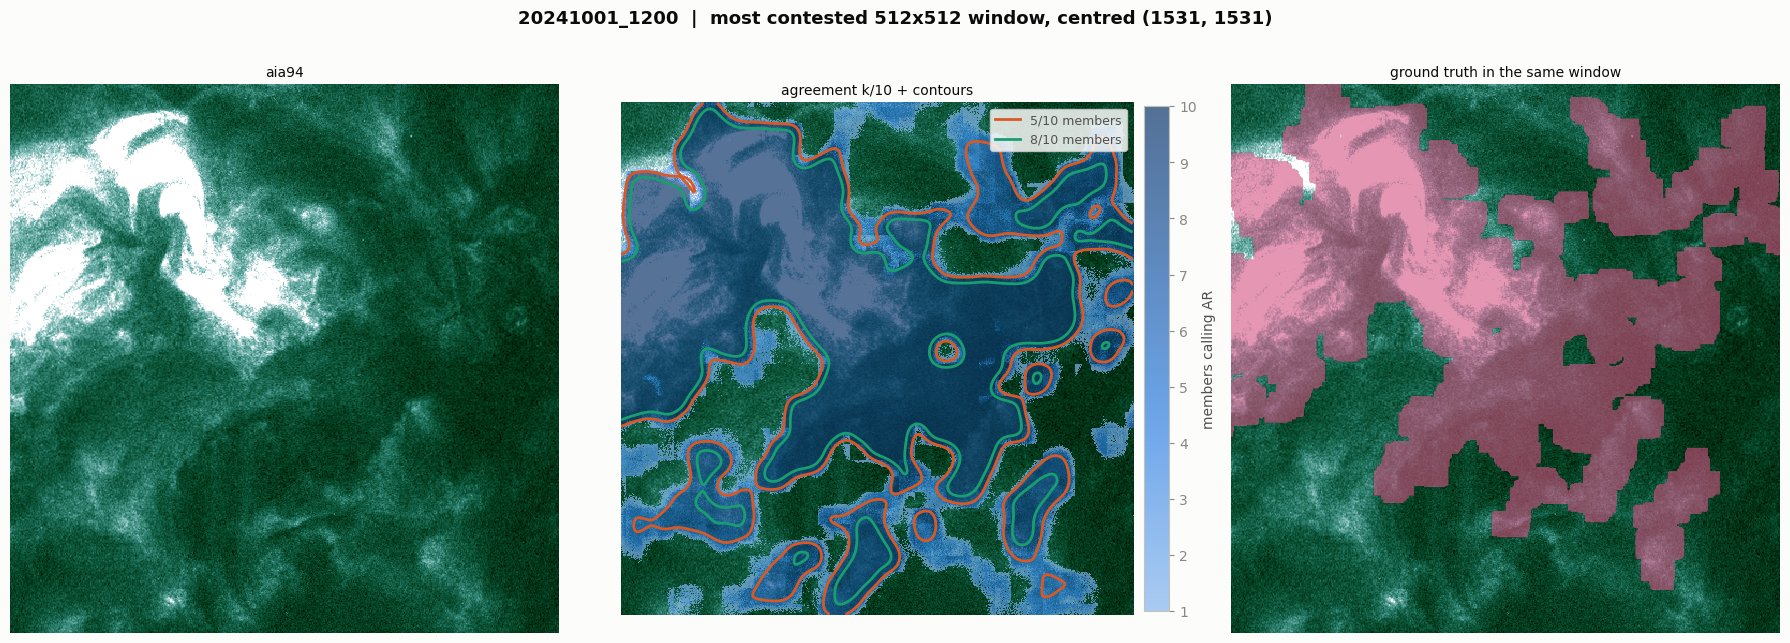

in this window: 176,830 px called AR by >=1 member, 89,767 px by all 10
contested (1..9 members): 87,063 px
ground truth in window: 123,315 px (47.04 % of the window)

of the window's truth pixels, 98.1 % were called AR by at least one member, 71.3 % by all 10


In [9]:
from scipy.ndimage import uniform_filter

contested = (count > 0) & (count < N)
WIN = 512
density = uniform_filter(contested.astype(np.float32), size=WIN, mode="constant")
cy, cx = np.unravel_index(np.argmax(density), density.shape)
y0, x0 = max(0, cy - WIN // 2), max(0, cx - WIN // 2)
y1, x1 = min(H, y0 + WIN), min(W, x0 + WIN)

# Smooth the whole frame, then crop. Smoothing the crop instead would treat the window
# edge as the end of the data and bend the contour there.
smoothed = fcolor.smooth_to_model_resolution(count / N, fcolor.SURYA_PATCH_PX)
print(f"smoothed with FWHM {fcolor.SURYA_PATCH_PX} px "
      f"(sigma {fcolor.SURYA_PATCH_PX / 2.3548:.2f} px);  "
      f"raw max {(count / N).max():.2f} -> smoothed max {smoothed.max():.2f}")

sub_img = image[y0:y1, x0:x1]
sub_cnt = count[y0:y1, x0:x1]
sub_truth = truth[y0:y1, x0:x1]
fraction = smoothed[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 3, figsize=(18, 6.4))
fig.suptitle(f"{FRAME}  |  most contested {WIN}x{WIN} window, centred ({cy}, {cx})",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.02)

for ax in axes:
    ax.imshow(sub_img, cmap=ev.channel_cmap(CHANNEL), vmin=vmin, vmax=vmax,
              interpolation="nearest")
    ax.axis("off")
axes[0].set_title(f"{CHANNEL}", fontsize=10, color=ev.INK)

im = axes[1].imshow(np.ma.masked_where(sub_cnt == 0, sub_cnt), cmap=ev.SEQ_AGREE,
                    norm=Normalize(1, N), alpha=0.7, interpolation="nearest")
handles = []
for level, colour in sorted(ev.CONTOUR.items()):
    if (fraction >= level).any() and not (fraction >= level).all():
        axes[1].contour(fraction, levels=[level], colors=[colour], linewidths=2)
        handles.append(plt.Line2D([], [], color=colour, lw=2,
                                  label=f"{int(round(level * N))}/{N} members"))
    else:
        print(f"  contour {level:.1f} EMPTY -- smoothed field never crosses it here")
axes[1].set_title(f"agreement k/{N} + contours", fontsize=10, color=ev.INK)
if handles:
    axes[1].legend(handles=handles, loc="upper right", fontsize=9, framealpha=0.85,
                   labelcolor=ev.INK_2)
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.02).set_label(
    "members calling AR", color=ev.INK_2)

axes[2].imshow(np.ma.masked_where(~sub_truth, np.ones_like(sub_img)),
               cmap=ListedColormap([ev.MASK_FILL]), alpha=0.6, vmin=0, vmax=1)
axes[2].set_title("ground truth in the same window", fontsize=10, color=ev.INK)

plt.tight_layout()
plt.show()

n_any = int(np.count_nonzero(sub_cnt > 0))
n_all = int(np.count_nonzero(sub_cnt == N))
print(f"in this window: {n_any:,} px called AR by >=1 member, {n_all:,} px by all {N}")
print(f"contested (1..{N - 1} members): "
      f"{int(np.count_nonzero((sub_cnt > 0) & (sub_cnt < N))):,} px")
print(f"ground truth in window: {int(np.count_nonzero(sub_truth)):,} px "
      f"({100 * sub_truth.mean():.2f} % of the window)")
print(f"\nof the window's truth pixels, {100 * (sub_cnt[sub_truth] > 0).mean():.1f} % "
      f"were called AR by at least one member, "
      f"{100 * (sub_cnt[sub_truth] == N).mean():.1f} % by all {N}")

### Is the disagreement boundary-shaped or detection-shaped?

A boundary disagreement puts contested pixels in a thin rind around a core every member
found. A missed-detection disagreement puts them in solid blobs no core sits inside. The
agreement histogram over the whole frame separates the two: a confident ensemble is
**U-shaped** (pixels are either unanimously AR or unanimously not), a disagreeing one is
flat.

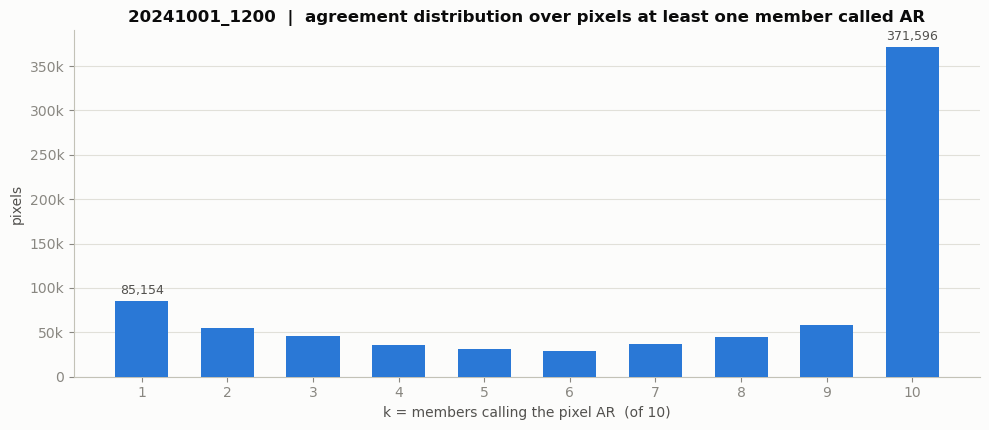

k = 0 (nobody called AR): 15,984,669 px (95.28 % of frame) -- reported, not drawn; it would flatten every other bar
k >= 1: 792,547 px   of which unanimous (k = 10): 371,596 (46.9 %)
contested (1 <= k <= 9): 420,951 px (53.1 % of all predicted-AR pixels)

of the 649,280 true AR pixels frame-wide, 92.3 % were found by >=1 member and 56.3 % by all 10


In [10]:
levels = np.arange(1, N + 1)
counts = np.array([int(np.count_nonzero(count == k)) for k in levels])
none = int(np.count_nonzero(count == 0))

fig, ax = plt.subplots(figsize=(10, 4.4))
# Single series -> single colour, no legend; the title names it.
ax.bar(levels, counts, width=0.62, color=ev.SERIES_1, zorder=3)
ax.set_xticks(levels)
ax.set_xlabel(f"k = members calling the pixel AR  (of {N})")
ax.set_ylabel("pixels")
ax.set_title(f"{FRAME}  |  agreement distribution over pixels at least one member called AR",
             fontsize=12, fontweight="bold", color=ev.INK)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:,.0f}k" if v else "0")
# Label the two ends only -- the shape is the message, not twelve numbers.
for k in (levels[0], levels[-1]):
    c = counts[k - 1]
    ax.annotate(f"{c:,}", (k, c), xytext=(0, 5), textcoords="offset points",
                ha="center", fontsize=9, color=ev.INK_2)
ev.recessive(ax)
plt.tight_layout()
plt.show()

any_ar = int(counts.sum())
print(f"k = 0 (nobody called AR): {none:,} px ({100 * none / count.size:.2f} % of frame) "
      "-- reported, not drawn; it would flatten every other bar")
print(f"k >= 1: {any_ar:,} px   of which unanimous (k = {N}): {counts[-1]:,} "
      f"({100 * counts[-1] / any_ar:.1f} %)")
print(f"contested (1 <= k <= {N - 1}): {any_ar - counts[-1]:,} px "
      f"({100 * (any_ar - counts[-1]) / any_ar:.1f} % of all predicted-AR pixels)")
print(f"\nof the {int(np.count_nonzero(truth)):,} true AR pixels frame-wide, "
      f"{100 * (count[truth] > 0).mean():.1f} % were found by >=1 member "
      f"and {100 * (count[truth] == N).mean():.1f} % by all {N}")

## 6. How well located is the boundary?

§5 shows the disagreement is a boundary rind. This turns that into a distance: **how far
is the AR edge from where the ensemble puts it?**

The quantity is the **mean uncertainty in the position of the $\bar p = 0.5$ contour**,
and it is computed two independent ways. They rest on different assumptions, so
agreement between them is the check that either is meaningful.

**Method B — empirical boundary distance (the headline).** The average symmetric surface
distance (ASSD) between each member's own $p_m = 0.5$ boundary and the ensemble-mean
boundary. Makes no model of the field at all: extract both boundaries, Euclidean-distance
transform one, sample it on the other, and average both directions. The same machinery
run against the ground-truth mask gives the boundary **error**.

**Method A — gradient error propagation (the cross-check, and the map).** Linearizing the
level-set displacement gives

$$\sigma_r = \frac{\sigma_p}{|\nabla \bar p|}$$

evaluated on the boundary — the implicit-function statement that a probability wobble of
$\sigma_p$ moves the 0.5 crossing by $\sigma_p$ divided by the local slope. Method B
cannot produce a per-pixel map; this can.

**On the raw $\bar p$ gradient, not a smoothed one.** §5 smooths the agreement field
because $k/10$ is quantized to ten values and genuinely staircased. $\bar p$ is not: it
is an average of ten continuous maps and varies smoothly *inside* a patch (median
within-patch range 0.547, measured below). Smoothing it to one patch FWHM flattens the
gradient and inflates $\sigma_r$ to a median of 13.2 px — which would be a property of
the smoothing kernel, not of the ensemble.

**HD95 is the 95th-percentile Hausdorff distance** -- a tail measure of how far two boundaries get from each other.
The plain Hausdorff distance is the worst case: for every pixel on boundary A, find the distance to the nearest pixel on boundary B, and take the maximum. It's a standard segmentation metric but it's notoriously fragile — one stray pixel 400 px away sets the whole number. HD95 replaces the max with the 95th percentile, keeping the "how bad does it get" character while discarding the top 5 % of outliers.

### Two things to hold on to before reading the numbers

**One Surya patch is 16 px, and that is the model's resolution floor.** Any boundary
agreement finer than that is agreement about something the decoder cannot actually
resolve. Expect the median to sit well inside one patch and read the *tail* and the
*across-member spread* as the signal.

**Uncertainty is not error.** Member scatter about the ensemble boundary measures only
what the bootstrap can see. All ten members share one training distribution and the same
6x class-balance shift, so any bias common to all of them is invisible to the spread. The
ground-truth row is there to measure exactly that gap.

In [11]:
import json

from scipy.ndimage import binary_erosion, distance_transform_edt

# Plate scale from the cube's own WCS rather than a hardcoded constant, so this stays
# right if FRAME changes. rsun_ref is in METRES (6.96e8), hence the /1000 for km.
with xr.open_dataset(os.path.join(FRAME_DIR, "prob_boot01.nc"), engine="h5netcdf") as ds:
    source_nc = ds.attrs["source_file"]
with xr.open_dataset(source_nc) as cube:  # lazy: reads attrs, not the 322 MB of data
    wcs = json.loads(cube[list(cube.data_vars)[0]].attrs["meta_1"])
ARCSEC_PER_PX = float(wcs["cdelt1"])
RSUN_OBS = float(wcs["rsun_obs"])            # arcsec
KM_PER_PX = ARCSEC_PER_PX / RSUN_OBS * float(wcs["rsun_ref"]) / 1000.0
PATCH_PX = fcolor.SURYA_PATCH_PX
print(f"plate scale: {ARCSEC_PER_PX} arcsec/px, rsun_obs {RSUN_OBS:.2f} arcsec "
      f"-> {KM_PER_PX:.1f} km/px at disk centre")


def boundary(mask):
    """Inner boundary: mask pixels with at least one 8-neighbour outside the mask.

    Erosion with a full 3x3 removes everything not completely surrounded, so what is
    left of `mask & ~eroded` is exactly the one-pixel rind. 8-connectivity rather than
    4 so diagonal steps of a staircased edge count once, not twice.
    """
    return mask & ~binary_erosion(mask, np.ones((3, 3), bool))


def surface_distances(a, b, dist_to_a=None):
    """Both directions of boundary-to-boundary distance between masks `a` and `b`.

    Returns (d_b_to_a, d_a_to_b) in pixels. Reported separately, never pre-averaged:
    the asymmetry says which boundary is longer and more convoluted, and collapsing to
    ASSD first throws that away.

    `dist_to_a` is the EDT of a's boundary, passed in when it is reused across many
    calls -- it is the expensive half (~1.3 s on 4096^2) and the ensemble boundary is
    the same for all ten members.
    """
    ba, bb = boundary(a), boundary(b)
    if dist_to_a is None:
        dist_to_a = distance_transform_edt(~ba)
    return dist_to_a[bb], distance_transform_edt(~bb)[ba]


B_ens = boundary(soft_pred)
dist_to_ens = distance_transform_edt(~B_ens)  # computed once, reused ten times

rows = []
ecdf = {}
for member in MEMBERS:
    mask = load_probability(member) > THRESHOLD
    d_m2e, d_e2m = surface_distances(soft_pred, mask, dist_to_ens)
    pooled = np.concatenate([d_m2e, d_e2m])
    ecdf[member] = pooled
    rows.append({
        "name": member, "kind": "member",
        "n_boundary_px": int(np.count_nonzero(boundary(mask))),
        "d_member_to_ens": float(d_m2e.mean()), "d_ens_to_member": float(d_e2m.mean()),
        "assd_px": 0.5 * (d_m2e.mean() + d_e2m.mean()),
        "median_px": float(np.median(pooled)), "hd95_px": float(np.percentile(pooled, 95)),
    })
    del mask, d_m2e, d_e2m

# The same measurement against truth. This is ERROR, not uncertainty.
d_t2e, d_e2t = surface_distances(soft_pred, truth, dist_to_ens)
pooled_t = np.concatenate([d_t2e, d_e2t])
ecdf["ground truth"] = pooled_t
rows.append({
    "name": "ground truth", "kind": "truth",
    "n_boundary_px": int(np.count_nonzero(boundary(truth))),
    "d_member_to_ens": float(d_t2e.mean()), "d_ens_to_member": float(d_e2t.mean()),
    "assd_px": 0.5 * (d_t2e.mean() + d_e2t.mean()),
    "median_px": float(np.median(pooled_t)), "hd95_px": float(np.percentile(pooled_t, 95)),
})

bd = pd.DataFrame(rows)
bd["assd_arcsec"] = bd.assd_px * ARCSEC_PER_PX
bd["assd_km"] = bd.assd_px * KM_PER_PX

mem = bd[bd.kind == "member"]
gtr = bd[bd.kind == "truth"].iloc[0]
UNC = float(mem.assd_px.mean())
UNC_SD = float(mem.assd_px.std(ddof=1))
ERR = float(gtr.assd_px)

out = bd[["name", "n_boundary_px", "d_member_to_ens", "d_ens_to_member", "assd_px",
          "median_px", "hd95_px", "assd_arcsec", "assd_km"]].copy()
out.columns = ["", "boundary px", "->ens", "ens->", "ASSD px", "median", "HD95",
               "ASSD arcsec", "ASSD km"]
print(out.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print(f"\nensemble-mean boundary: {int(np.count_nonzero(B_ens)):,} px "
      f"for {100 * soft_pred.mean():.3f} % predicted area")
print(f"\n--- UNCERTAINTY (members about the ensemble-mean boundary) ---")
print(f"  mean ASSD   {UNC:.2f} +/- {UNC_SD:.2f} px   "
      f"= {UNC * ARCSEC_PER_PX:.2f} arcsec = {UNC * KM_PER_PX:,.0f} km at disk centre")
print(f"  median      {np.median(mem.median_px):.2f} px   "
      f"mean HD95 {mem.hd95_px.mean():.1f} px")
print(f"  per member  {mem.assd_px.min():.2f} ({mem.loc[mem.assd_px.idxmin(), 'name']}) "
      f"- {mem.assd_px.max():.2f} ({mem.loc[mem.assd_px.idxmax(), 'name']}) px")
print(f"  for scale, one Surya patch is {PATCH_PX} px "
      f"({PATCH_PX * ARCSEC_PER_PX:.1f} arcsec)")
print(f"\n--- ERROR (ensemble-mean boundary against ground truth) ---")
print(f"  ASSD {ERR:.2f} px = {ERR * ARCSEC_PER_PX:.2f} arcsec = {ERR * KM_PER_PX:,.0f} km"
      f"   median {gtr.median_px:.2f}  HD95 {gtr.hd95_px:.1f} px")
print(f"\n  error / uncertainty = {ERR / UNC:.2f}x")

plate scale: 0.6 arcsec/px, rsun_obs 958.57 arcsec -> 435.7 km/px at disk centre


              boundary px  ->ens  ens->  ASSD px  median  HD95  ASSD arcsec  ASSD km
      boot01        61014   3.58   2.76     3.17    1.00 11.70         1.90  1380.09
      boot02        93401  11.67   1.70     6.68    1.41 46.10         4.01  2910.42
      boot03        57156   4.56   5.34     4.95    2.00 18.03         2.97  2157.19
      boot04        79134   4.44   3.02     3.73    1.41 15.00         2.24  1625.74
      boot05        62131   3.39   4.48     3.93    1.00 13.42         2.36  1713.18
      boot06        84261  11.67   3.35     7.51    3.00 42.72         4.51  3271.96
      boot07        84537   4.36   1.31     2.84    1.00 13.42         1.70  1235.29
      boot08       117076  14.19   1.73     7.96    2.00 60.17         4.78  3467.12
      boot09        57335   3.68  10.32     7.00    2.00 38.08         4.20  3051.07
      boot10        66242   7.52   2.02     4.77    1.00 20.00         2.86  2077.62
ground truth        32166  10.28  11.48    10.88    4.24 54.57   

In [12]:
# --- the probability-space reading of the same question
sigma_prob = float(p_sd[B_ens].mean())
print(f"mean per-pixel sd of p-bar ON the boundary: {sigma_prob:.4f}  "
      f"(median {float(np.median(p_sd[B_ens])):.4f})")

# --- Method A: sigma_r = sigma_p / |grad p-bar|, on the raw field
gy, gx = np.gradient(p_mean)
grad = np.hypot(gy, gx)
del gy, gx
with np.errstate(divide="ignore", invalid="ignore"):
    sigma_r = (p_sd / grad).astype(np.float32)
sr_b = sigma_r[B_ens]
sr_b = sr_b[np.isfinite(sr_b)]
print(f"\nMethod A  sigma_r on the boundary: mean {sr_b.mean():.2f} px  "
      f"median {np.median(sr_b):.2f}  p90 {np.percentile(sr_b, 90):.1f}")
print(f"Method B  mean ASSD:               mean {UNC:.2f} px  "
      f"median {np.median(mem.median_px):.2f}")
print(f"  the two estimators agree to {abs(sr_b.mean() - UNC) / UNC * 100:.0f} % on the mean")

# --- the two sanity checks the method rests on, measured rather than asserted
blocks = p_mean.reshape(H // PATCH_PX, PATCH_PX, W // PATCH_PX, PATCH_PX)
touching = B_ens.reshape(H // PATCH_PX, PATCH_PX, W // PATCH_PX, PATCH_PX).any(axis=(1, 3))
within = float(np.median((blocks.max(axis=(1, 3)) - blocks.min(axis=(1, 3)))[touching]))
yy, xx = np.indices(p_mean.shape)
on_seam = ((yy % PATCH_PX) == 0) | ((xx % PATCH_PX) == 0) | \
          ((yy % PATCH_PX) == PATCH_PX - 1) | ((xx % PATCH_PX) == PATCH_PX - 1)
print(f"\nis p-bar smooth inside a patch?  median within-patch range on boundary patches "
      f"{within:.3f}")
print("  -> not flat, so the raw gradient is a real slope and smoothing it first would "
      "be wrong")
print(f"patch-seam bias:  mean |grad| on seams {grad[B_ens & on_seam].mean():.5f}  vs "
      f"interior {grad[B_ens & ~on_seam].mean():.5f} "
      f"({grad[B_ens & on_seam].mean() / grad[B_ens & ~on_seam].mean():.2f}x)")
print("  -> Method A runs slightly optimistic where the boundary sits on a seam; "
      "that is why B is the headline")

# --- de-projected km, for a complex spanning 135 deg of longitude
r_arcsec = np.hypot(yy - (H - 1) / 2, xx - (W - 1) / 2) * ARCSEC_PER_PX
mu = np.sqrt(np.clip(1.0 - (r_arcsec / RSUN_OBS) ** 2, 0.0, None))
del yy, xx, r_arcsec, on_seam
mu_b = mu[B_ens]
keep = mu_b >= 0.3
print(f"\nforeshortening: mu on the boundary median {np.median(mu_b):.3f}, "
      f"{100 * (~keep).mean():.1f} % below 0.3 (excluded from the de-projected figure)")
print(f"  on-surface displacement, de-projected by 1/mu: "
      f"{UNC * KM_PER_PX * float(np.mean(1 / mu_b[keep])):,.0f} km")
print(f"  that treats the displacement as radial (the foreshortened direction), so it is "
      f"an upper bound;\n  the tangential case is the undeprojected "
      f"{UNC * KM_PER_PX:,.0f} km. The truth is between them.")

mean per-pixel sd of p-bar ON the boundary: 0.2298  (median 0.2245)



Method A  sigma_r on the boundary: mean 5.18 px  median 3.17  p90 9.8
Method B  mean ASSD:               mean 5.25 px  median 1.41
  the two estimators agree to 1 % on the mean



is p-bar smooth inside a patch?  median within-patch range on boundary patches 0.590
  -> not flat, so the raw gradient is a real slope and smoothing it first would be wrong
patch-seam bias:  mean |grad| on seams 0.10658  vs interior 0.07074 (1.51x)
  -> Method A runs slightly optimistic where the boundary sits on a seam; that is why B is the headline



foreshortening: mu on the boundary median 0.865, 4.1 % below 0.3 (excluded from the de-projected figure)
  on-surface displacement, de-projected by 1/mu: 2,849 km
  that treats the displacement as radial (the foreshortened direction), so it is an upper bound;
  the tangential case is the undeprojected 2,289 km. The truth is between them.


### Where the boundary is loose

$\sigma_r$ on §5's contested window, over the channel image, with the ensemble-mean
boundary drawn on it. A wide bright rind is a boundary the ensemble cannot place; a thin
one is an edge every member agrees on.

**Drawn only on the transition band $0.1 < \bar p < 0.9$.** Away from the boundary the
ratio $\sigma_p / |\nabla \bar p|$ divides a near-zero numerator by a near-zero
denominator — it is numerical noise, it has no boundary to be the uncertainty *of*, and
rendered frame-wide it swamps the rind with the patch grid. Restricting to the band is
what makes the quantity mean what the formula says it means.

Values are clipped at one patch rather than rescaled, so the colour carries the same
meaning it does elsewhere in this notebook.

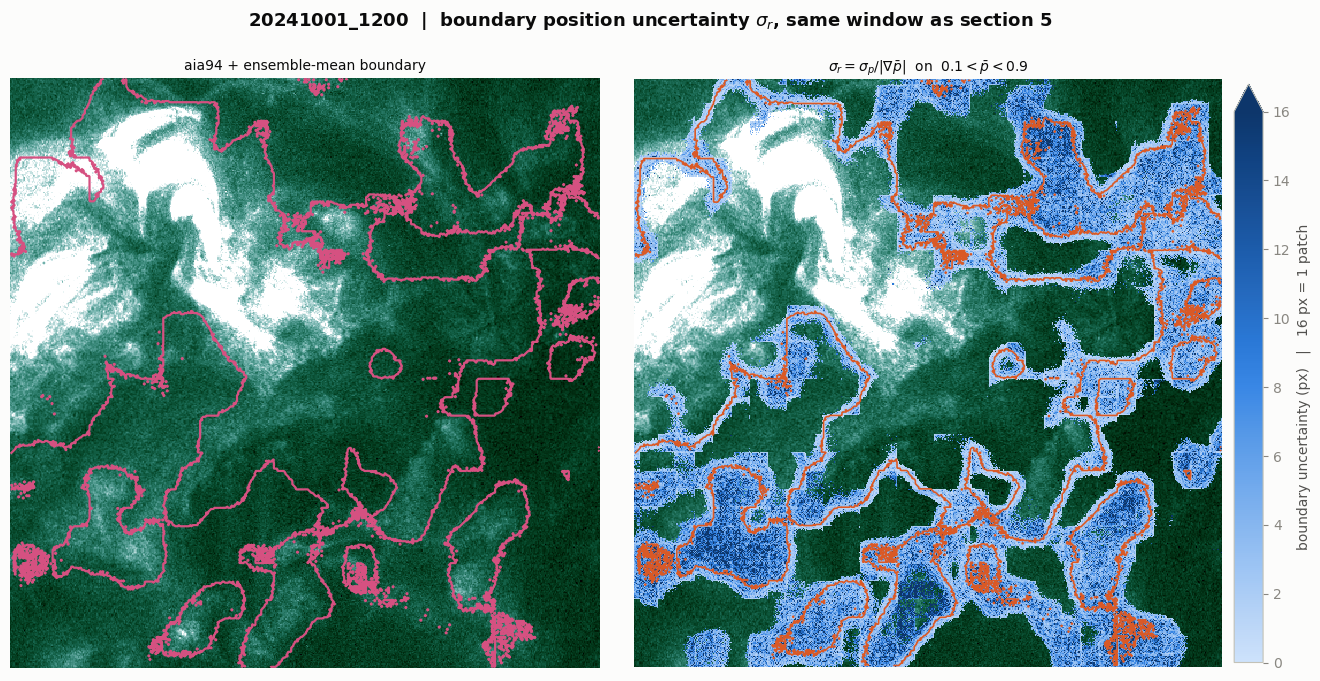

in this window, sigma_r on the boundary: median 3.38 px, 4.4 % exceed one patch
the transition band covers 42.9 % of the window; its median sigma_r is 4.23 px


In [13]:
sub_sigma = sigma_r[y0:y1, x0:x1]
sub_soft = soft_pred[y0:y1, x0:x1]
sub_pm = p_mean[y0:y1, x0:x1]
# The band where a 0.5 crossing could actually sit. Outside it sigma_r is 0/0 noise.
band = (sub_pm > 0.1) & (sub_pm < 0.9) & np.isfinite(sub_sigma)
# Ceiling at one patch: beyond that the boundary is unresolved by construction, and a
# handful of near-zero-gradient pixels would otherwise set the whole scale.
VMAX = PATCH_PX

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.6))
fig.suptitle(f"{FRAME}  |  boundary position uncertainty $\\sigma_r$, same window as section 5",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.02)

for ax in axes:
    ax.imshow(sub_img, cmap=ev.channel_cmap(CHANNEL), vmin=vmin, vmax=vmax,
              interpolation="nearest")
    ax.axis("off")

axes[0].contour(sub_soft.astype(float), levels=[0.5], colors=[ev.MASK_FILL], linewidths=1.6)
axes[0].set_title(f"{CHANNEL} + ensemble-mean boundary", fontsize=10, color=ev.INK)

im = axes[1].imshow(np.ma.masked_where(~band, sub_sigma), cmap=ev.SEQ,
                    vmin=0, vmax=VMAX, interpolation="nearest")
axes[1].contour(sub_soft.astype(float), levels=[0.5], colors=[ev.CONTOUR[0.5]], linewidths=1.2)
axes[1].set_title(r"$\sigma_r = \sigma_p / |\nabla \bar p|$  on  $0.1 < \bar p < 0.9$",
                  fontsize=10, color=ev.INK)
cb = fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.02, extend="max")
cb.set_label(f"boundary uncertainty (px)   |   {VMAX} px = 1 patch", color=ev.INK_2)

plt.tight_layout()
plt.show()

w_sig = sub_sigma[np.isfinite(sub_sigma) & boundary(sub_soft)]
print(f"in this window, sigma_r on the boundary: median {np.median(w_sig):.2f} px, "
      f"{100 * (w_sig > PATCH_PX).mean():.1f} % exceed one patch")
print(f"the transition band covers {100 * band.mean():.1f} % of the window; "
      f"its median sigma_r is {np.median(sub_sigma[band]):.2f} px")

### The whole distribution, not just its mean

The mean and the median of these distances are far apart, so neither alone describes the
boundary. This is the cumulative distribution of every boundary-to-boundary distance:
read off any point as *"this fraction of boundary pixels lie within x px"*.

Ten members in grey, ground truth in orange — the **emphasis** form, because the story is
the one curve that sits apart from the others, not ten equally interesting ones. The gap
between the grey band and the orange curve **is** the gap between what the bootstrap
thinks it knows and how wrong it actually is.

Log x-axis: the distances span three decades, and on a linear axis the entire grey band
collapses onto the left edge.

*Palette note.* The grey `#898781` against the orange `#eb6834` fails only the
validator's **chroma floor**, on the grey, which is by design — a de-emphasis grey is
deliberately not a categorical slot, and the validator's scope line says "categorical
palettes only". Everything load-bearing passes: CVD ΔE 9.8, normal-vision ΔE 17.6, and
both clear 3:1 against the surface.

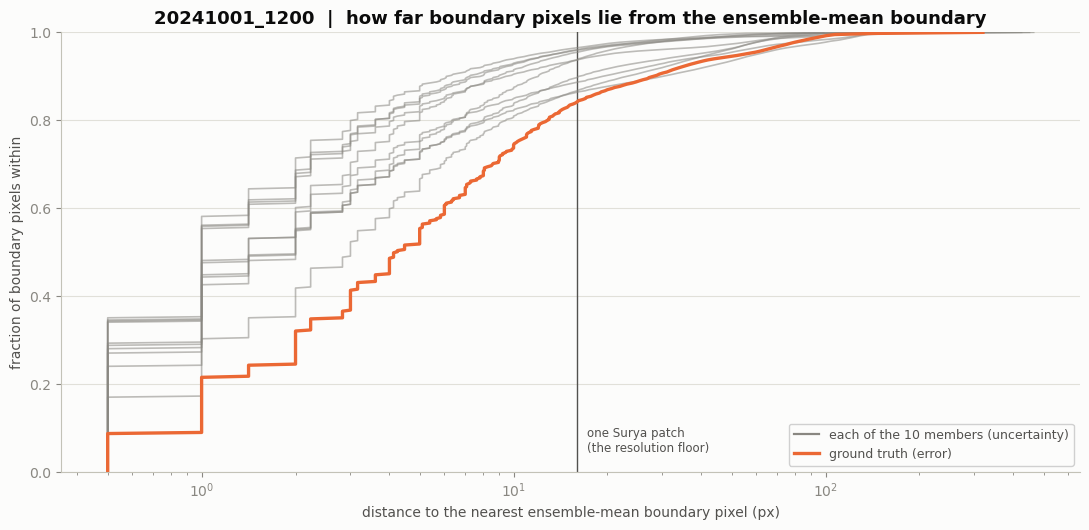

members (pooled)   within 1 patch (16 px):  92.0 %   median  1.41 px   mean   5.99 px
ground truth       within 1 patch (16 px):  84.3 %   median  4.24 px   mean  11.03 px

The mean sits far above the median in both because a tail of small detached islands
lies a long way from the main edge. HD95 bounds that tail: 28 px for the members, 55 px for truth.


In [14]:
fig, ax = plt.subplots(figsize=(11, 5.4))
ax.set_title(f"{FRAME}  |  how far boundary pixels lie from the ensemble-mean boundary",
             fontsize=13, fontweight="bold", color=ev.INK)


def ecdf_xy(d, n_pts=400):
    """Sub-sampled ECDF. Plotting 10^5 identical steps is slow and looks the same."""
    s = np.sort(d)
    q = np.linspace(0, 1, n_pts)
    return np.maximum(np.quantile(s, q), 0.5), q  # floor at half a px for the log axis


for member in MEMBERS:
    x, y = ecdf_xy(ecdf[member])
    ax.plot(x, y, color=ev.MUTED, lw=1.2, alpha=0.55, zorder=2)
x, y = ecdf_xy(ecdf["ground truth"])
ax.plot(x, y, color=ev.SERIES_2, lw=2.4, zorder=4)

ax.axvline(PATCH_PX, color=ev.INK_2, lw=1.0, zorder=1)
ax.annotate("one Surya patch\n(the resolution floor)", (PATCH_PX, 0.04), xytext=(7, 0),
            textcoords="offset points", fontsize=8.5, color=ev.INK_2, va="bottom")
ax.set_xscale("log")
ax.set_xlabel("distance to the nearest ensemble-mean boundary pixel (px)")
ax.set_ylabel("fraction of boundary pixels within")
ax.set_ylim(0, 1)
ev.recessive(ax)

handles = [plt.Line2D([], [], color=ev.MUTED, lw=1.6,
                      label=f"each of the {N} members (uncertainty)"),
           plt.Line2D([], [], color=ev.SERIES_2, lw=2.4,
                      label="ground truth (error)")]
ax.legend(handles=handles, loc="lower right", fontsize=9, framealpha=0.9,
          labelcolor=ev.INK_2)
plt.tight_layout()
plt.show()

for label, d in [("members (pooled)", np.concatenate([ecdf[m] for m in MEMBERS])),
                 ("ground truth", ecdf["ground truth"])]:
    print(f"{label:<18} within 1 patch ({PATCH_PX} px): {100 * (d <= PATCH_PX).mean():5.1f} %"
          f"   median {np.median(d):5.2f} px   mean {d.mean():6.2f} px")
print(f"\nThe mean sits far above the median in both because a tail of small detached "
      f"islands\nlies a long way from the main edge. HD95 bounds that tail: "
      f"{mem.hd95_px.mean():.0f} px for the members, {gtr.hd95_px:.0f} px for truth.")

## 7. Calibration — can $\bar p$ be read as a probability?

Bin pixels by $\bar p$ and plot the observed ground-truth frequency in each bin. A
perfectly calibrated $\bar p$ lands on the diagonal: pixels where the ensemble says 0.3
are AR 30 % of the time. Departures say which way it is wrong — below the diagonal is
over-confident, above it is under-confident.

**A different axis from §6, and the two must not be merged.** §6 asked whether the member
*spread* is an honest error bar on the boundary's **position**. This asks whether the
value $\bar p$ is an honest frequency for a pixel's **class**. One can be under-confident
while the other is over-confident, and on this frame they are — reading either as "the
ensemble is (over/under)-confident" full stop would be wrong.

**Restricted to pixels where at least one member fired.** The $k=0$ population is ~96 %
of the frame and would sit entirely in the first bin, so it sets the curve's left end on
its own and tells you nothing about the rest. Its ground-truth frequency is printed
separately, because for this frame — where the truth mask is 6x denser than anything
trained on — the AR content hiding in $k=0$ is part of the story.

Bin counts are in the lower panel on a log scale, **not** on a second y-axis: a bin
holding 40 pixels and one holding $10^7$ must not be drawn as equals, and two scales on
one plot would invent a relationship between frequency and count that isn't there.

In [15]:
fired = count > 0
pm = p_mean[fired]
tm = truth[fired]

EDGES = np.linspace(0.0, 1.0, 11)
idx = np.clip(np.digitize(pm, EDGES) - 1, 0, len(EDGES) - 2)
rel = pd.DataFrame({
    "bin_lo": EDGES[:-1], "bin_hi": EDGES[1:],
    "n": np.bincount(idx, minlength=10).astype(np.int64),
    "n_true": np.bincount(idx, weights=tm.astype(np.float64), minlength=10).astype(np.int64),
    "mean_p": np.bincount(idx, weights=pm.astype(np.float64), minlength=10),
})
rel["mean_p"] = np.where(rel.n > 0, rel.mean_p / rel.n.where(rel.n > 0, 1), np.nan)
rel["observed"] = np.where(rel.n > 0, rel.n_true / rel.n.where(rel.n > 0, 1), np.nan)
# A bin thinner than this is drawn hollow: its frequency is noise, not a measurement.
MIN_N = 1000
rel["reliable"] = rel.n >= MIN_N

print(rel.assign(
    bin=lambda d: d.bin_lo.map("{:.1f}".format) + "-" + d.bin_hi.map("{:.1f}".format)
)[["bin", "n", "n_true", "mean_p", "observed", "reliable"]].to_string(
    index=False, float_format=lambda x: f"{x:.4f}", na_rep="-"))

n_quiet = int(np.count_nonzero(~fired))
quiet_true = float(truth[~fired].mean())
print(f"\nexcluded (k = 0): {n_quiet:,} px ({100 * n_quiet / count.size:.2f} % of frame), "
      f"ground-truth AR frequency {quiet_true:.5f}")
print(f"  that is {int(np.count_nonzero(truth & ~fired)):,} true AR pixels no member "
      f"found at all -- {100 * np.count_nonzero(truth & ~fired) / np.count_nonzero(truth):.1f} % "
      "of the frame's AR")
thin_bins = list(rel.index[~rel.reliable & rel.n.gt(0)])
print(f"\nbins below the {MIN_N:,}-pixel reliability floor: "
      + (f"{thin_bins} -- drawn hollow, their frequencies are noise"
         if thin_bins else "none; every non-empty bin is a real measurement"))

    bin      n  n_true  mean_p  observed  reliable
0.0-0.1   5612    1333  0.0874    0.2375      True
0.1-0.2  43929   10211  0.1558    0.2324      True
0.2-0.3  67852   19884  0.2517    0.2930      True
0.3-0.4  67485   27133  0.3485    0.4021      True
0.4-0.5  55190   29675  0.4487    0.5377      True
0.5-0.6  48634   33889  0.5493    0.6968      True
0.6-0.7  53577   43888  0.6522    0.8192      True
0.7-0.8  62804   54042  0.7501    0.8605      True
0.8-0.9  70698   64540  0.8530    0.9129      True
0.9-1.0 316766  314547  0.9773    0.9930      True

excluded (k = 0): 15,984,669 px (95.28 % of frame), ground-truth AR frequency 0.00314
  that is 50,138 true AR pixels no member found at all -- 7.7 % of the frame's AR

bins below the 1,000-pixel reliability floor: none; every non-empty bin is a real measurement


every non-empty bin clears the 1,000-pixel floor -- floor line not drawn


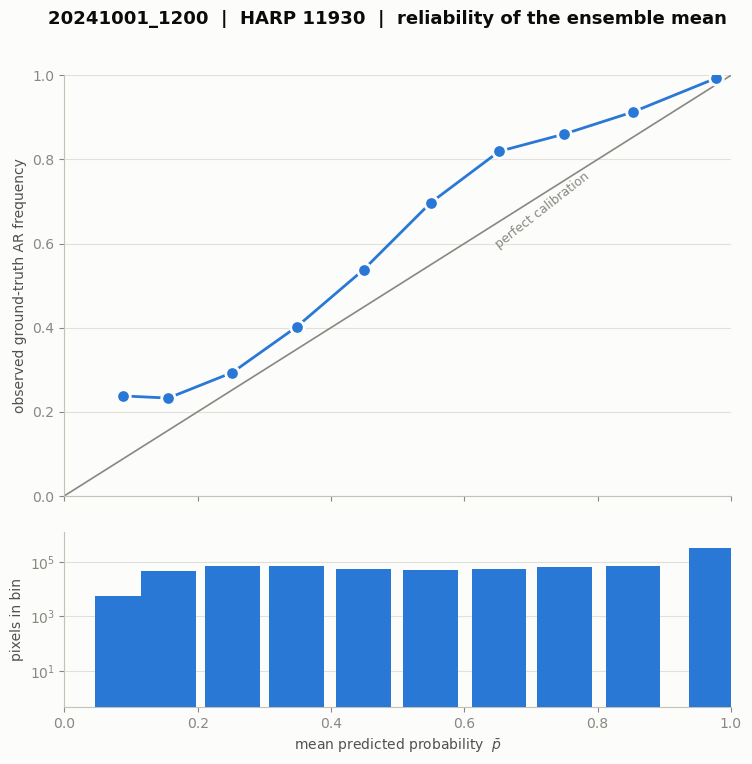

Brier score over the 792,547 pixels where >=1 member fired: 0.1148
  mean p-bar 0.6957   observed AR frequency 0.7560   bias -0.0603
  weighted mean |observed - p-bar| over reliable bins: 0.0603


In [16]:
ok = rel.reliable & rel.n.gt(0)

fig, (ax, axc) = plt.subplots(
    2, 1, figsize=(8.6, 8.2), sharex=True,
    gridspec_kw={"height_ratios": [2.4, 1], "hspace": 0.12})
fig.suptitle(f"{FRAME}  |  HARP {HARPNUM}  |  reliability of the ensemble mean",
             fontsize=13, fontweight="bold", color=ev.INK, y=0.96)

# Reference line, not a gridline -- solid and directly labelled so it cannot be read
# as chrome (the palette's grid is a lighter step and carries no label).
ax.plot([0, 1], [0, 1], color=ev.MUTED, lw=1.2, zorder=2)
ax.annotate("perfect calibration", (0.72, 0.72), xytext=(0, -14),
            textcoords="offset points", ha="center", fontsize=9, color=ev.MUTED,
            rotation=38, rotation_mode="anchor")

ax.plot(rel.mean_p[ok], rel.observed[ok], color=ev.SERIES_1, lw=2, zorder=3)
ax.scatter(rel.mean_p[ok], rel.observed[ok], s=95, color=ev.SERIES_1, zorder=4,
           edgecolors=plt.rcParams["figure.facecolor"], linewidths=2,
           label=f"bin with $\\geq$ {MIN_N:,} px")
thin = (~rel.reliable) & rel.n.gt(0)
if thin.any():
    ax.scatter(rel.mean_p[thin], rel.observed[thin], s=95, facecolors="none",
               edgecolors=ev.SERIES_1, linewidths=2, zorder=4,
               label=f"bin with < {MIN_N:,} px (noise)")
    # Only then is there a second thing to tell apart; one series needs no legend box.
    ax.legend(loc="upper left", fontsize=9, framealpha=0.9, labelcolor=ev.INK_2)
ax.set_ylabel("observed ground-truth AR frequency")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ev.recessive(ax)

axc.set_yscale("log")
# Only non-empty bins: a zero-height bar on a log axis has no defined bottom, and an
# empty bin is honestly absent rather than drawn at some floor value.
nonempty = rel.n > 0
axc.bar(rel.mean_p[nonempty], rel.n[nonempty], width=0.082, color=ev.SERIES_1,
        bottom=0.5, zorder=3)
axc.set_ylim(0.5, float(rel.n.max()) * 4)
if thin.any():
    # Only draw the threshold when something is actually on the wrong side of it.
    # The bars span the full panel height, so an uncrossed line is a rule laid over
    # data for no reason.
    axc.axhline(MIN_N, color=ev.MUTED, lw=1.0, zorder=4)
    axc.annotate(f"{MIN_N:,} px reliability floor", (0.02, MIN_N), xytext=(0, 5),
                 textcoords="offset points", fontsize=8.5, color=ev.MUTED, zorder=5)
else:
    print(f"every non-empty bin clears the {MIN_N:,}-pixel floor "
          "-- floor line not drawn")
axc.set_xlabel(r"mean predicted probability  $\bar p$")
axc.set_ylabel("pixels in bin")
ev.recessive(axc)
plt.show()

# Brier score and the two decomposable pieces, over the same restricted population.
brier = float(np.mean((pm - tm) ** 2))
print(f"Brier score over the {len(pm):,} pixels where >=1 member fired: {brier:.4f}")
print(f"  mean p-bar {pm.mean():.4f}   observed AR frequency {tm.mean():.4f}   "
      f"bias {pm.mean() - tm.mean():+.4f}")
w = rel.n[ok] / rel.n[ok].sum()
print(f"  weighted mean |observed - p-bar| over reliable bins: "
      f"{float((w * (rel.observed[ok] - rel.mean_p[ok]).abs()).sum()):.4f}")

## 8. Cache the combined ensemble

`ensemble_mean.nc` next to the member files: the mean, the sd, the agreement count and
the ground truth as it was read here. §4's numbers and any later cross-frame comparison
then cost one 100 MB read instead of re-reading 335 MB of member maps and re-deriving
everything.

float32 for the two continuous fields (fp16 would re-quantize what is already a
fp16-sourced average), uint8 for the count and the mask.

§6's boundary statistics go in as **attributes, not variables**. The $\sigma_r$ map
recomputes in ~30 s and would add 67 MB to a 168 MB file; the scalars are what a later
cross-frame comparison actually needs, and they sit beside the IoUs already stored the
same way.

In [17]:
out_path = os.path.join(FRAME_DIR, "ensemble_mean.nc")

ds = xr.Dataset(
    data_vars={
        "ar_probability_mean": (("y", "x"), p_mean),
        "ar_probability_sd": (("y", "x"), p_sd),
        "agreement_count": (("y", "x"), count),
        "ground_truth": (("y", "x"), truth.astype(np.uint8)),
    },
    attrs={
        "title": f"Bootstrap ensemble mean AR segmentation, {N} members",
        "regime": "672hr",
        "train_samples": 672,
        "frame": FRAME,
        "harpnum": HARPNUM,
        "data_time": str(pd.read_csv(os.path.join(INFER_ROOT, "manifest.csv"))
                         .query("file == @FRAME").data_time.iloc[0]),
        "members": " ".join(MEMBERS),
        "best_epochs": " ".join(f"{m}:{BEST[m][0]}" for m in MEMBERS),
        "threshold": THRESHOLD,
        "vote_min": VOTE_MIN,
        "source_dir": FRAME_DIR,
        "truth_source": TRUTH_PATH,
        "truth_key": TRUTH_KEY,
        "truth_positive_fraction": truth_frac,
        "soft_mean_iou": float(soft.iou),
        "hard_vote_iou": float(hard.iou),
        "median_member": median_member["name"],
        "median_member_iou": float(median_member.iou),
        # Section 6. Uncertainty is member scatter about the ensemble boundary; error is
        # the ensemble boundary against truth. They are different quantities -- stored
        # under names that keep them apart.
        "boundary_assd_px": UNC,
        "boundary_assd_sd_px": UNC_SD,
        "boundary_median_px": float(np.median(mem.median_px)),
        "boundary_hd95_px": float(mem.hd95_px.mean()),
        "boundary_error_assd_px": ERR,
        "boundary_error_median_px": float(gtr.median_px),
        "boundary_error_over_uncertainty": ERR / UNC,
        "boundary_sigma_prob": sigma_prob,
        "arcsec_per_px": ARCSEC_PER_PX,
        "km_per_px_disk_centre": KM_PER_PX,
        "geometry": "north-up, crpix 2048.5, 0.6 arcsec/px, 4096x4096 -- same as the .nc cube",
        "note": ("2024 frame, outside the 2011-2019 fine-tuning span. Mask is "
                 f"{truth_frac / TRAIN_TRUE_FRAC:.1f}x denser than the training-era "
                 "validation set, so IoU here is not comparable to the 0.52-0.63 "
                 "validation IoUs the members were selected on."),
    },
)
ds.to_netcdf(out_path, engine="h5netcdf")
ds.close()

# Verify what landed on disk, rather than trusting what was handed to the writer.
with xr.open_dataset(out_path, engine="h5netcdf") as chk:
    pm_chk = chk.ar_probability_mean.values
    cnt_chk = chk.agreement_count.values
    print(f"wrote {out_path}  ({os.path.getsize(out_path) / 1e6:.0f} MB)")
    print(f"  ar_probability_mean  {pm_chk.dtype}  "
          f"[{pm_chk.min():.4f}, {pm_chk.max():.4f}]  "
          f"in [0,1]: {bool(pm_chk.min() >= 0 and pm_chk.max() <= 1)}")
    print(f"  ar_probability_sd    {chk.ar_probability_sd.values.dtype}")
    print(f"  agreement_count      {cnt_chk.dtype}  "
          f"[{cnt_chk.min()}, {cnt_chk.max()}]  "
          f"integer in [0,{N}]: {bool(cnt_chk.min() >= 0 and cnt_chk.max() <= N)}")
    print(f"  ground_truth         {chk.ground_truth.values.dtype}  "
          f"positive fraction {float(chk.ground_truth.values.mean()):.6f}")
    bnd_attrs = {k: v for k, v in chk.attrs.items() if k.startswith("boundary_")}
    bad = [k for k, v in bnd_attrs.items() if not np.isfinite(v)]
    print(f"  boundary attrs       {len(bnd_attrs)} stored, all finite: {not bad}"
          + (f"  *** non-finite: {bad} ***" if bad else ""))
    for k, v in bnd_attrs.items():
        print(f"      {k:<34}{v:.4f}")

# The frame-mean of p-bar must equal the mean of the ten members' own frame-means.
# Equality is exact in real arithmetic; fp16 storage of each member map is the only
# source of disagreement, so the tolerance is set by fp16, not by the averaging.
per_member_means = np.array([float(load_probability(m).mean()) for m in MEMBERS])
print(f"\nmean-is-a-mean check")
print(f"  frame-mean of p-bar                     {pm_chk.mean():.8f}")
print(f"  mean of the ten member frame-means      {per_member_means.mean():.8f}")
print(f"  |difference|                            "
      f"{abs(float(pm_chk.mean()) - per_member_means.mean()):.2e}  (fp16 eps ~ 1e-3)")

wrote /efs/bathomas/ar_seg_bootstrap/672hr_infer_holdout_top3/20241001_1200/ensemble_mean.nc  (168 MB)
  ar_probability_mean  float32  [0.0000, 1.0000]  in [0,1]: True
  ar_probability_sd    float32
  agreement_count      uint8  [0, 10]  integer in [0,10]: True
  ground_truth         uint8  positive fraction 0.038700
  boundary attrs       8 stored, all finite: True
      boundary_assd_px                  5.2541
      boundary_assd_sd_px               1.8884
      boundary_median_px                1.4142
      boundary_hd95_px                  27.8628
      boundary_error_assd_px            10.8812
      boundary_error_median_px          4.2426
      boundary_error_over_uncertainty   2.0710
      boundary_sigma_prob               0.2298



mean-is-a-mean check
  frame-mean of p-bar                     0.03496361
  mean of the ten member frame-means      0.03496356
  |difference|                            5.27e-08  (fp16 eps ~ 1e-3)


## What this frame says

The five questions this notebook was built to answer, and how they came out on the 672 hr
ensemble. Every number below is produced by the cells above — nothing here is asserted
independently. §9 then asks the sixth question, the one only this notebook can ask: what
did 4x the training data change?

**1. Does averaging ten members beat picking one blind? Yes, and by more than the 168 hr
ensemble managed.** The soft mean scores **0.7395** IoU against the median member's
**0.7006** — **+0.0389**, which is **1.35x** the entire across-member sd (0.0288). It also
beats the **best** member (boot10, 0.7351) by +0.0044, which is the stronger result: the
best member is chosen *using* the answer, so the ensemble is winning against a baseline it
has no right to beat.

**2. Soft mean or hard vote? Soft mean, by +0.0073 IoU.** The two rules disagree on
20,363 pixels (0.12 % of the frame) — about a third fewer than the 168 hr ensemble's
31,672, because these members agree with each other more. The hard vote is again the more
conservative rule: it buys precision (0.931 vs 0.925) and pays more recall than it gains
(0.775 vs 0.787).

**3. Area error or localization error? Localization, again, and the area error is mild.**
Eight of ten members under-predict, the mean member covers **0.871x** the true AR area and
the soft mean **0.851x** — so against a mask 6.02x denser than anything these models
trained on, they still track the area to within 13-15 %. The IoU shortfall is about *which*
pixels, not how many.

§5 locates it, and the structure has shifted from the 168 hr case: **53.1 %** of all
predicted-AR pixels are contested (168 hr: 60.8 %) and **56.3 %** of true AR pixels are
found by all ten (168 hr: 53.3 %). These members agree with each other more.

But they collectively reach *less*: **92.3 %** of true AR pixels are found by at least one
member, down from 95.1 %, leaving **7.7 % of the frame's AR (50,138 px) found by no member
at all** — up from 4.9 %. That is the part of the mask no threshold change can recover, and
it got bigger. More training data bought consensus at the cost of the ensemble's reach.

**4. How well located is the boundary, and is the spread an honest error bar? Located to
~5 px; the error bar is still too small, by ~2.1x.** Member boundaries sit a mean
**5.25 ± 1.89 px** from the ensemble-mean boundary — **3.15 arcsec**, about **2,290 km** at
disk-centre scale, well inside the 16 px the decoder can resolve. The two independent
estimators agree to **1 %** (empirical boundary distance 5.25 px, gradient propagation
5.18 px), which is what makes either meaningful.

The ensemble-mean boundary sits **10.88 px** from the *true* boundary. The spread
understates the error by **2.07x** — better than the 168 hr ensemble's 2.22x, but the
failure mode is unchanged and expected: all ten members share one training distribution and
the same 6x class-balance shift, so **a bootstrap measures variance and is blind to bias.**
The member scatter remains a lower bound on boundary error, never an estimate of it.

Read the median (1.41 px) next to the mean. 92.0 % of member boundary pixels lie within one
patch; the mean is carried by a tail of small detached islands, which HD95 bounds at ~28 px
for the members and ~55 px for truth.

**5. Can $\bar p$ be used as a probability? No — and it is *more* under-confident than the
168 hr ensemble.** The reliability curve sits above the diagonal in **all ten** bins (168 hr:
nine of ten). Pixels the ensemble puts at 0.45 are AR **54 %** of the time; pixels at 0.65
are AR **82 %** of the time. Mean $\bar p$ is 0.696 where the observed frequency is 0.756, a
bias of **−0.060**, and the weighted mean absolute calibration error is **0.060** — both
worse than the 168 hr ensemble's −0.047 / 0.048, even though the Brier score *improved*
(0.1148 vs 0.1283). Those two move in opposite directions because Brier rewards sharpness
and this ensemble is sharper; being sharper while still biased low makes the miscalibration
larger, not smaller.

This remains the actionable finding, and the case for it is now stronger: under-confidence in
every bin, plus eight of ten members under-predicting area, both point the same way —
**0.5 is the wrong threshold on this frame**, and more clearly so than before. The
IoU-optimal threshold here is **0.35**, worth **+0.0156** IoU (0.7395 → 0.7551), with a
broad optimum — anything in 0.30–0.45 lands within 0.005. That is the cheap fix, and the
broad optimum is what makes it cheap: one parameter, estimable from a handful of frames.
(In-sample on this frame — the size of the prize, not a usable threshold.)

**The real fix is *not* a class-balance correction**, which is the obvious reading of
caveat 2 and is wrong. Correcting $\bar p$ analytically for the 6x prior shift (odds ×
6.22, for 0.643 % → 3.87 %) makes calibration **2.2x worse**: the weighted calibration
error goes 0.060 → 0.134, overshooting in all ten bins. §4 says why — the ensemble already
adapts its area to the frame, predicting 3.29 % AR where the mask is 3.87 %, not the
0.64 % its training prior alone would suggest. Its probabilities are not "calibrated for a
0.643 % prior" waiting to be shifted; the −0.060 bias is the residual *after* the model's
own adaptation.

What would work is fitting the map **empirically on holdout-era frames**, which makes
"holdout-era" a statement about which frames you pool rather than a correction factor. The
binding constraint there is effective sample size, not pixel count: this frame has 792,547
fired pixels but its truth mask is **14 connected components** (6 above 10k px), and the
resolution floor is one 16 px patch — so it carries on the order of ten effective samples,
and pixel-count error bars on a reliability curve would be optimistic by a factor of ~250.
Match the fitted parameters to that. A threshold (1 parameter) is estimable from a few
frames; Platt or Beta scaling (2–3) needs tens of distinct ARs; isotonic regression
(~10 knots) needs hundreds. Error bars must come from a block bootstrap over ARs or frames,
never over pixels.

### Two caveats that survive all five

**One frame.** The across-member sd is measured over ten members on a single realization, so
"+0.0389 for averaging" has no error bar on it yet.

**Validation IoU did not predict holdout IoU.** Ranking the ten members by the validation
score they were selected on against their IoU on this frame gives a Spearman correlation of
**0.08** (p = 0.83). The two best-validating members (boot05 at 0.6341, boot03 at 0.6169)
land 8th and 9th of ten here; boot08, the *worst* validator at 0.5177 and a one-epoch model,
lands 7th and within 0.042 of the best. The 168 hr ensemble showed the same thing more
weakly (Spearman 0.37, p = 0.29). With n = 10 neither is significant and this notebook
cannot distinguish 0.08 from 0.37 — but nothing here supports treating "best epoch by
validation IoU" as a selection that transfers to a holdout-era frame. It is a defensible
rule for picking *a* checkpoint, not evidence that the picked one is better out of span.

Next, if this is worth extending: the other two top-three holdout frames are staged at
`/efs/bathomas/assets/holdout_top3_nc/`, and both *are* EUV-flaring at their instant — the
controlled comparison for whether flare emission widens member spread. Point
`run_bootstrap_inference.py --regime 672hr` at a directory holding one of them and re-run
this notebook with `FRAME` changed; §8's cache keeps each frame's scalars for the comparison.


## 9. 168 hr vs 672 hr — does 4x the training data buy anything?

The one question this notebook exists to answer that the 168 hr one could not. Both
regimes ran the **same ten bootstrap seeds** on the **same frame** against the **same
ground truth**, and both cached their results as `ensemble_mean.nc` attributes in §8, so
the comparison is a read of two attribute dictionaries — no re-inference, no 4096² loads.

What differs is only how much data each member saw: 168 samples (one week, hourly) against
672 (one month, hourly). Two things to watch, and they are not the same thing:

- **Accuracy.** Soft-mean IoU, and the gain over the median member. More data should help.
- **Honesty of the error bar.** The 168 hr ensemble's member spread understated its true
  boundary error by **2.2x** — a bootstrap sees variance and is blind to bias shared by all
  its members. If 672 hr members agree with each other *more* while staying the same
  distance from truth, that ratio gets **worse**, and a tighter-looking ensemble would be a
  more confidently wrong one. `boundary_error_over_uncertainty` is the number to read.


In [18]:
sibling_path = os.path.join(SIBLING_ROOT, FRAME, "ensemble_mean.nc")

with xr.open_dataset(out_path, engine="h5netcdf") as a, \
     xr.open_dataset(sibling_path, engine="h5netcdf") as b:
    this, other = dict(a.attrs), dict(b.attrs)

# Both files must describe the same frame and the same truth mask, or nothing below is a
# comparison. Checked rather than assumed -- the two were written three days apart.
assert other["frame"] == this["frame"], "different frames"
assert abs(other["truth_positive_fraction"] - this["truth_positive_fraction"]) < 5e-5, \
    "different truth masks"
print(f"both cached ensembles describe frame {this['frame']}, "
      f"truth fraction {this['truth_positive_fraction']:.6f}  -- comparable\n")

# "better" is the direction that is an improvement, used only to pick the arrow below.
# None where the metric has a target rather than a direction (area ratio wants 1.0).
METRICS = [
    ("soft-mean IoU",               "soft_mean_iou",                    "up"),
    ("hard-vote IoU",               "hard_vote_iou",                    "up"),
    ("median-member IoU",           "median_member_iou",                "up"),
    ("boundary ASSD (uncertainty)", "boundary_assd_px",                 None),
    ("boundary sd across members",  "boundary_assd_sd_px",              None),
    ("boundary median",             "boundary_median_px",               None),
    ("boundary HD95",               "boundary_hd95_px",                 None),
    ("boundary ERROR vs truth",     "boundary_error_assd_px",           "down"),
    ("error / uncertainty",         "boundary_error_over_uncertainty",  "down"),
    ("sigma_p on the boundary",     "boundary_sigma_prob",              None),
]

rows_cmp = []
for label, key, direction in METRICS:
    v168, v672 = float(other[key]), float(this[key])
    delta = v672 - v168
    if direction is None:
        arrow = ""
    elif (delta > 0) == (direction == "up"):
        arrow = "better" if delta else ""
    else:
        arrow = "worse" if delta else ""
    rows_cmp.append({"metric": label, "168hr": v168, "672hr": v672,
                     "delta": delta, "672hr is": arrow})

# Ensemble gain over the blind baseline: the claim that averaging is worth doing at all.
gain = {r: float(d["soft_mean_iou"]) - float(d["median_member_iou"])
        for r, d in (("168hr", other), ("672hr", this))}
rows_cmp.append({"metric": "ensemble gain over median", "168hr": gain["168hr"],
                 "672hr": gain["672hr"], "delta": gain["672hr"] - gain["168hr"],
                 "672hr is": "better" if gain["672hr"] > gain["168hr"] else "worse"})

cmp_tbl = pd.DataFrame(rows_cmp)
print(cmp_tbl.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

print(f"\nmember selection (validation, 0.643 % positive class):")
print(f"  168hr  mean val IoU 0.5116   range 0.4812-0.5539   P/R 0.669/0.669")
print(f"  672hr  mean val IoU {np.mean([v[1] for v in BEST.values()]):.4f}   "
      f"range {min(v[1] for v in BEST.values()):.4f}-"
      f"{max(v[1] for v in BEST.values()):.4f}   P/R {TRAIN_PREC:.3f}/{TRAIN_REC:.3f}")
print(f"\nbest epochs   168hr  {other['best_epochs']}")
print(f"              672hr  {this['best_epochs']}")


both cached ensembles describe frame 20241001_1200, truth fraction 0.038700  -- comparable

                     metric    168hr    672hr   delta 672hr is
              soft-mean IoU  +0.7013  +0.7395 +0.0383   better
              hard-vote IoU  +0.6914  +0.7322 +0.0409   better
          median-member IoU  +0.6780  +0.7006 +0.0227   better
boundary ASSD (uncertainty)  +6.3619  +5.2541 -1.1077         
 boundary sd across members  +2.7156  +1.8884 -0.8272         
            boundary median  +1.4142  +1.4142 +0.0000         
              boundary HD95 +23.9905 +27.8628 +3.8723         
    boundary ERROR vs truth +14.1072 +10.8812 -3.2260   better
        error / uncertainty  +2.2175  +2.0710 -0.1465   better
    sigma_p on the boundary  +0.2866  +0.2298 -0.0568         
  ensemble gain over median  +0.0233  +0.0389 +0.0156   better

member selection (validation, 0.643 % positive class):
  168hr  mean val IoU 0.5116   range 0.4812-0.5539   P/R 0.669/0.669
  672hr  mean val IoU 0.591

### The same comparison as a chart

Only the metrics that share a unit can share an axis, so this is two panels: the three
IoUs on the left (dimensionless, 0–1), the boundary distances on the right (pixels). The
error/uncertainty ratio is in the table above and nowhere here — it is a ratio of two
quantities already plotted, and drawing it alongside them would double-count.

Paired dots joined by a line, 168 hr in blue and 672 hr in orange: the line length *is*
the change, and the slope direction carries its sign without needing a legend entry per
metric. One Surya patch (16 px) is marked on the right panel because it is the resolution
floor any boundary number has to be read against.


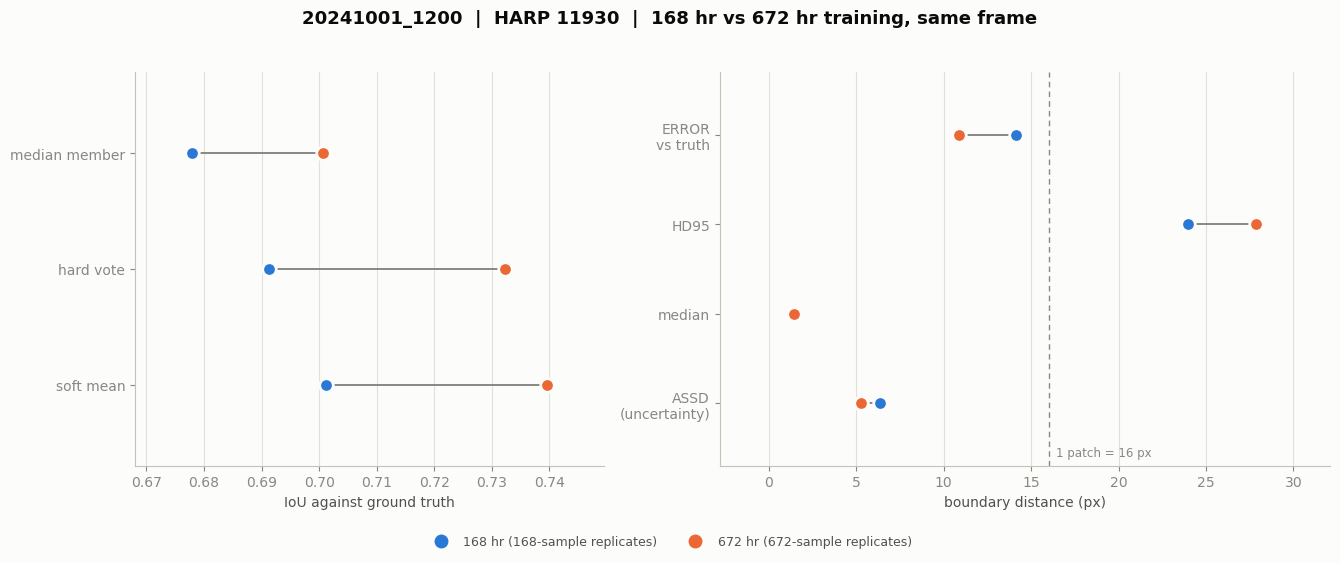

In [19]:
IOU_KEYS = [("soft mean", "soft_mean_iou"), ("hard vote", "hard_vote_iou"),
            ("median member", "median_member_iou")]
PX_KEYS = [("ASSD\n(uncertainty)", "boundary_assd_px"),
           ("median", "boundary_median_px"),
           ("HD95", "boundary_hd95_px"),
           ("ERROR\nvs truth", "boundary_error_assd_px")]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0),
                         gridspec_kw={"width_ratios": [1, 1.3]})
fig.suptitle(f"{FRAME}  |  HARP {HARPNUM}  |  168 hr vs 672 hr training, same frame",
             fontsize=13, fontweight="bold", color=ev.INK, y=1.03)

for ax, keys, xlabel in [(axes[0], IOU_KEYS, "IoU against ground truth"),
                         (axes[1], PX_KEYS, "boundary distance (px)")]:
    y = np.arange(len(keys))
    v168 = np.array([float(other[k]) for _, k in keys])
    v672 = np.array([float(this[k]) for _, k in keys])
    # Connector first, at a lower zorder: it is the change, the dots are the endpoints.
    for i in y:
        ax.plot([v168[i], v672[i]], [i, i], color=ev.MUTED, lw=1.4, zorder=2)
    ring = dict(edgecolors=plt.rcParams["figure.facecolor"], linewidths=2, zorder=3, s=95)
    ax.scatter(v168, y, c=ev.SERIES_1, **ring)
    ax.scatter(v672, y, c=ev.SERIES_2, **ring)
    ax.set_yticks(y)
    ax.set_yticklabels([lab for lab, _ in keys])
    ax.set_ylim(-0.7, len(keys) - 0.3)
    ax.set_xlabel(xlabel)
    lo, hi = float(min(v168.min(), v672.min())), float(max(v168.max(), v672.max()))
    m = max((hi - lo) * 0.16, 0.01)
    ax.set_xlim(lo - m, hi + m)
    ev.recessive(ax, grid_axis="x")

# One patch, on the pixel panel only -- it has no meaning on an IoU axis.
if axes[1].get_xlim()[0] < PATCH_PX < axes[1].get_xlim()[1]:
    axes[1].axvline(PATCH_PX, color=ev.MUTED, lw=1.0, ls=(0, (4, 3)), zorder=1)
    axes[1].annotate(f"1 patch = {PATCH_PX} px", (PATCH_PX, -0.55), xytext=(5, 0),
                     textcoords="offset points", va="center", fontsize=8.5,
                     color=ev.MUTED)
else:
    print(f"one patch ({PATCH_PX} px) is outside the plotted range -- line not drawn")

handles = [plt.Line2D([], [], marker="o", ls="none", ms=9, color=ev.SERIES_1,
                      label="168 hr (168-sample replicates)"),
           plt.Line2D([], [], marker="o", ls="none", ms=9, color=ev.SERIES_2,
                      label="672 hr (672-sample replicates)")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=9, frameon=False,
           labelcolor=ev.INK_2, bbox_to_anchor=(0.5, -0.07))
plt.tight_layout()
plt.show()


## What this comparison says

**4x the training data bought real accuracy.** Soft-mean IoU went **0.7013 → 0.7395**
(+0.0383) on the identical frame against the identical mask, the hard vote gained slightly
more (+0.0409), and the median member — the blind-pick baseline — gained +0.0227. Averaging
also got *more* worthwhile, not less: the ensemble's gain over its median member grew
**0.0233 → 0.0389**. That is not what you would get if more data were simply making ten
members converge on one answer.

**And real boundary accuracy.** The ensemble-mean boundary moved from **14.11 px** to
**10.88 px** from truth — a 23 % reduction, or about 1,400 km at disk-centre scale. In a task
whose resolution floor is one 16 px patch, that takes the ensemble-mean boundary from
0.88 of a patch away from truth to 0.68 of a patch.

**The error bar got more honest, but only just.** This was the thing worth watching, because
it could have gone the other way: member spread tightened substantially (ASSD 6.36 → 5.25 px,
across-member sd 2.72 → 1.89, $\sigma_p$ on the boundary 0.287 → 0.230), and a tighter spread
around an unchanged error would have made the ensemble *more* confidently wrong. It did not
happen — error fell faster than spread, so `error / uncertainty` improved **2.22 → 2.07**.

But read the size of that improvement. The bootstrap still understates its own boundary error
by **a factor of two**, after quadrupling the training data. The 2x is not a small-sample
artifact that more data dissolves; it is the structural blindness, and it barely moved. All
ten members in both regimes share one training distribution and the same 6x class-balance
shift, and no amount of resampling *within* that distribution can see a bias common to all of
it. **If you need an error bar on the boundary, the bootstrap spread is not it — in either
regime.**

**Two things got worse, and they are the same thing.** HD95 rose **23.99 → 27.86 px**: the
tail of small detached islands got *further* from the ensemble boundary even as the main edge
tightened. And the ensemble's collective reach shrank — true AR pixels found by at least one
member fell **95.1 % → 92.3 %**, so the share found by nobody rose **4.9 % → 7.7 %**. Both say
the 672 hr members are more alike. Where the 168 hr ensemble had ten noisier models whose
disagreements between them covered more of the mask, this one has ten models that agree, and
what they agree to miss is missed for good. Diversity was doing real work in the weaker
ensemble, and some of it was lost.

**Calibration got worse too** — bias −0.047 → −0.060, every bin now under-confident rather
than nine of ten — even as Brier improved 0.1283 → 0.1148. The 672 hr ensemble is sharper and
no better centred, which is exactly the combination that makes a threshold of 0.5 wrong.

### The short version

More data is worth having: +0.038 IoU and −3.2 px of boundary error on a clean holdout frame,
for nothing but training time. It did **not** fix the two things a user of these masks would
most want fixed — the error bar still understates error 2x, and $\bar p$ still cannot be read
as a probability. Both are bias problems, and neither is addressable by more bootstrap
replicates or more samples per replicate. They need a **holdout-era calibration set**: frames
drawn from the 2020–2024 test era, spanning many distinct ARs, held out from both training and
from whatever frame you evaluate on. Not a class-balance correction — answer 5 of
"What this frame says" shows that correction going the wrong way in both regimes.

And note the exchange rate. Tuning the threshold on the *168 hr* ensemble is worth +0.0283 IoU
on this frame, which is **74 %** of the +0.0383 that quadrupling the training data bought — at
no training cost, from one fitted parameter. Whatever is spent on more data should be spent on
a calibration set first.

### What this comparison is not

**One frame, and one frame that is not typical.** Its mask is 6.02x denser than the
validation set both regimes were selected on, so every IoU here is on an easier class balance
than the selection numbers and the two notebooks are comparable only to *each other*.

**Not ten independent trials of "168 vs 672".** The two ensembles share their ten bootstrap
seeds but differ in a second way the design did not isolate: the 672 hr runs trained 5 epochs
(boot01 10) and peak at epochs 0–3, where the 168 hr runs trained 10–20 and peak at 3–9. Some
of what is attributed to "4x the data" above may be the shorter schedule or the earlier,
more aggressive best-epoch selection — caveat 3 in the header. Separating the two needs a
672 hr run trained to the same epoch count, which does not exist yet.
